# PDAN8412 Part 3: Sorting Waste Images with a Convolutional Neural Network

**Student:** Liam Knipe (ST10355049)
**Module:** PDAN8412 Programming for Data Analytics 2, Portfolio of Evidence Part 3
**Lecturer:** Dr Rudolf Holzhausen
**Dataset:** The Garbage Dataset (GD), Kunwar [1]. Data link: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2

**Sections**
1. Project context and hypothesis
2. Dataset evaluation and justification
3. Analysis plan
4. Imports and settings
5. Spark ingestion and image metadata
6. Quality checks and cleaning
7. Duplicate and label checks
8. Exploratory data analysis
9. What feature selection means for a CNN
10. Preprocessing, split and augmentation
11. Baselines
12. CNN v1
13. Evaluating CNN v1
14. Retraining (CNN v2)
15. Stress tests
16. Label check on confident mistakes
17. Business reading
18. Conclusion and limitations
19. References

## 1. Project context and hypothesis

The press has asked for image recognition at its premises. The brief allows any image task for now, with facial recognition as the longer-term aim. I chose waste sorting for this first step. A press produces a lot of paper and cardboard, its canteen and offices add plastic, glass, metal and food waste, and old devices leave batteries behind. A camera over a sorting point that tells staff which bin an item belongs in uses exactly the pipeline a face system would need later (camera, trained CNN, a decision, a record of mistakes), without the consent and POPIA questions that come with photographing people. I come back to that trade-off in Section 2.

The client question I'm answering is: **can a CNN trained from scratch sort photos of single waste items into ten material classes well enough to be trusted at a sorting point, and where does it fail?**

My expectation going in is that a small CNN will clearly beat simple baselines on macro F1, but that its mistakes will gather in materials that look alike in a photo (paper and cardboard, glass and plastic), which is also where the dataset's author found the most overlap [1]. I also expect part of what any model learns here to be *how* a photo was taken rather than *what* is in it, because the images come from very different sources. If a model that only sees image size and brightness scores well above chance, I'll treat the CNN's score with suspicion until the later checks say otherwise.

This notebook is my working record: what I did, what the output showed, and what I decided because of it.

## 2. Dataset evaluation and justification

### What a CNN needs from the data

A CNN learns its own features from pixels, so the data has to do more work than in Parts 1 and 2. It needs labelled images where the label describes what is in the picture, enough images per class for the network to see the same material in different shapes, colours and lighting, a format that can be brought to one size, and labels that are mostly right. It also needs the things that are *not* the label (background, camera, framing) to vary across classes, otherwise the network can score well by learning those instead.

### The Garbage Dataset

The Garbage Dataset (GD) was published by Kunwar in the *Journal of the Brazilian Computer Society* in June 2026 [1]. It has 12,259 JPEG images in ten classes: battery, biological, cardboard, clothes, glass, metal, paper, plastic, shoes and trash. According to the paper, 40.0% of the images come from public repositories and web scraping, 35.0% from the author's DWaste phone app and 25.0% from community submissions, and each image was labelled by hand and "verified by at least three volunteers" [1]. The author also reports a cleaning pass: one exact duplicate and 1,360 near-duplicates removed with a perceptual hash, plus 720 transparent, 20 non-RGB and 493 watermarked images taken out [1]. The data comes in three versions: the original files, and copies padded to 256 x 256 and 384 x 384 so the aspect ratio is kept.

That makes it a good fit on paper. It is well above the brief's 10,000-record minimum, it is recent and peer-reviewed, and the author documents its weak spots (class imbalance, brightness skewed towards over-exposure, busy backgrounds, and the highest outlier rates in plastic, cardboard and paper) [1]. I'd rather work with a dataset whose problems are written down, because then I can test them instead of defending them.

### Quality: what I take on trust and what I check

I can't re-check the volunteer labelling, so I treat the labels as mostly right and look for errors in two ways later: images that are near-copies of each other but carry different labels (Section 7), and the model's most confident mistakes (Section 16). Everything else the paper claims I check myself in Sections 5 to 8: the class counts, that no file is broken, that exact duplicates are gone, and whether near-duplicates are really gone.

### Balance

The paper reports glass as one of the biggest classes (1,736 images) and trash as the smallest (453, 3.7%) [1]. The imbalance is moderate rather than extreme, but it is enough that plain accuracy would flatter a model that does well on the big classes. I measure it in Section 8 and let it decide the metric.

### Does it look like the press's bins?

Only partly, and this is the biggest limit on what I can claim. Most battery and many cardboard images are product photos on a white background taken from the web, not items in a bin. Many biological images are stock photos of fresh fruit and vegetables. Clothes and shoes are mostly phone photos on floors and beds. A press would mostly see paper, cardboard, plastic wrap and the odd battery, often in poor light and in piles. Two of the classes (clothes and shoes) are unlikely at a press at all, and things a press does throw away, such as toner and ink cartridges, have no class. So a good test score here tells me the model can sort *this kind of photo*, not that it will work over the press's bins.

### Ethics and licence

The images show objects, not people, so this task avoids the personal-information questions that facial recognition would raise under POPIA. Some community photos are taken in homes, but I haven't seen identifiable people in the samples I looked at. The article is published under CC BY 4.0 [1], but the paper does not state a licence for the dataset itself, and I could not find one stated anywhere I could check. Because 40% of images came from unnamed public sources, the rights to individual images depend on those sources too, so I use the data for study only.

### The alternative I considered

The obvious alternative is TrashNet [2]: 2,527 photos in six classes (glass, paper, cardboard, plastic, metal, trash), taken on a white posterboard and resized to 512 x 384. It lost for two reasons. It is far below the 10,000-image minimum, and every photo has the same white background, so it can't tell me anything about messy real backgrounds. Section 7 shows a third reason I didn't expect when I started: a large part of TrashNet appears to already be inside GD.

### Pitfalls I'm watching for

Three problems are common in image data like this. **Near-duplicates** that end up on both sides of the train/test split make the test score too optimistic. **Shortcuts**: a network can score well by learning something that happens to go with a class in this dataset, such as the background or the image size, and then fail on new photos; Geirhos et al. call this shortcut learning [3]. **Label errors** in the test set: Northcutt et al. estimated an average of at least 3.3% label errors across ten popular benchmark test sets [4], which is enough to change which model looks best. Each of these gets its own check.

### What this data cannot answer

It can't tell me how the model does on the press's own bins, under the press's lighting, or on items it has never seen (toner cartridges). It can't tell me which source an image came from, so I can't test a phone-photo-only model. And because every image shows one main item, it says nothing about piles of mixed waste.

## 3. Analysis plan

The plan is short on purpose. The decision rules say what I will do depending on what the output shows.

| Step | What I will do | Why | Decision rule |
|---|---|---|---|
| Ingest (Spark) | Read all 12,259 originals and the 256 versions with Spark; build size, brightness, file-size and hash metadata and class aggregates | The brief requires Spark for the analysis | Any unreadable file is listed and dropped before the split |
| Quality | Broken files, formats, near-blank images, very small images | A broken or blank file teaches the model nothing | Near-blank images are looked at, not dropped automatically |
| Duplicates | Exact duplicates by MD5; near-duplicates with a two-stage difference hash | Copies across the split inflate the test score | Exact duplicates are dropped before splitting. Near-twins are counted across the split and reported |
| EDA | Class balance, size and shape by class, brightness, sample and mean images | Each finding has to change a modelling choice | Largest/smallest above 3 to 1 means stratified split and macro F1 |
| Shortcut baseline | Random forest on width, height, aspect ratio, brightness and file size only | Tests for shortcuts [3] | If it scores far above chance, the CNN's score is read with suspicion and the stress tests carry more weight |
| Other baselines | Majority class; a dense network on 32 x 32 pixels | A floor, and a check on what convolution adds | The CNN has to beat both on validation macro F1 |
| CNN v1 | 3 convolution blocks, dropout, softmax; Adam at 0.001 [5]; batch 32; up to 30 epochs; early stopping on validation loss (patience 5) | Small enough for an 8 GB laptop; Adam needs little tuning [5]; dropout limits overfitting [6] | Best epoch kept and saved; nothing slow is retrained |
| Evaluation | Macro F1 (main), accuracy, per-class precision, recall and F1, confusion matrix, learning curves, mistakes | Imbalance makes accuracy misleading | The model with the higher validation macro F1 is the one I report on the test set |
| Uncertainty | Bootstrap 95% intervals (1,000 resamples); McNemar's test between models on the same test images [7] | One test set, one training run | I only call a model better if the McNemar p-value is under 0.05 and the intervals tell the same story |
| Retrain (v2) | Name v1's main shortcoming, change one thing, same split and seed | The brief asks for a retrain that fixes a named weakness | Default change is class weights if the small classes lag |
| Stress tests | Darker, brighter, blurred, rotated and heavily compressed copies of the test set | Real bins are not studio photos | A drop of more than 10 macro-F1 points under a condition gets named as a deployment risk |
| Label check | Cross-class near-twins, then the 20 most confident test mistakes, by eye | Label errors change the ranking of models [4] | Every doubtful label is listed with its file name |
| Business | Battery recall on its own; cost of mistakes with batteries weighted ten times (my assumption) | A battery in general waste is a fire risk | The recommendation depends on battery recall, not on accuracy |

**Feature selection.** The brief asks for feature selection, but a CNN learns its own features from the pixels, so there is no list of columns to keep or drop with p-values as in Part 2. What I do choose is the input: its size (128 x 128), colour (RGB, because colour separates green glass from clear plastic), how pixel values are scaled, and which random changes (augmentation) the network sees during training. Section 9 sets those out. The shortcut baseline is the closest thing to classic feature selection here: it asks whether a handful of non-content features already predict the class.

## 4. Imports and settings

I import everything here so a missing package fails at the top and not halfway through. The first output prints the versions I ran with, and the seed is set once for Python, NumPy and TensorFlow.

In [1]:
# Standard library
import os
import io
import sys
import json
import time
import platform

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter

# Spark, used for ingestion and the metadata aggregates
import pyspark
from pyspark.sql import SparkSession, functions as F, types as T

# Modelling and evaluation
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, recall_score
from sklearn.utils.class_weight import compute_class_weight
import statsmodels
from statsmodels.stats.contingency_tables import mcnemar
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Same plot style as my Part 1 notebook
sns.set_style("whitegrid")

SEED = 42
# One call sets the Python, NumPy and TensorFlow seeds together
keras.utils.set_random_seed(SEED)

# Settings I might change. 96 is the fallback image size if memory runs short.
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 5
# False = load saved models if they exist. Set to True to force training again.
RETRAIN = False

# Relative paths only, so the notebook runs from the repo on any computer
DATA_DIR = os.path.join("..", "data")
ARTIFACTS = os.path.join("..", "artifacts")
FIG_DIR = os.path.join("..", "figures")
os.makedirs(ARTIFACTS, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

print("Python:", platform.python_version())
for name, mod in [("pyspark", pyspark), ("pandas", pd), ("numpy", np), ("scikit-learn", sklearn),
                  ("statsmodels", statsmodels), ("tensorflow", tf), ("keras", keras), ("seaborn", sns)]:
    print(f"{name}: {mod.__version__}")
print("---")
print("Seed:", SEED, "| image size:", IMG_SIZE, "| batch:", BATCH_SIZE, "| max epochs:", EPOCHS)
print("Data folders found:", sorted(os.listdir(DATA_DIR)))

Python: 3.13.11
pyspark: 4.2.0
pandas: 2.3.3
numpy: 2.5.3
scikit-learn: 1.9.1
statsmodels: 0.15.0
tensorflow: 2.21.0
keras: 3.15.1
seaborn: 0.13.2
---
Seed: 42 | image size: 128 | batch: 32 | max epochs: 30
Data folders found: ['original', 'standardized_256']


The versions above are the ones every result in this notebook comes from. The data folder should list `original` and `standardized_256`; the notebook needs both.

## 5. Spark ingestion and image metadata

The brief asks for Spark in the analysis of each part, and I'm using it the same way as in Part 2: Spark reads the raw files and builds the quality checks and summary tables, and the modelling happens in TensorFlow.

I read the **original** files with Spark's `binaryFile` reader, which gives me the raw bytes, the path and the file size for every image. A pandas UDF (a Python function Spark runs on batches of rows) then opens each image once and records its true width and height, format, mean brightness, contrast, and three small fingerprints I need for the duplicate check in Section 7. Spark's built-in `md5` gives me a fingerprint of the exact bytes for the exact-duplicate check.

I expect 12,259 rows, as the paper reports [1].

In [2]:
# Spark's Python workers must use this same environment, or the UDF can't find pyarrow and Pillow
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (SparkSession.builder
         .master("local[*]")
         .appName("PDAN8412_Part3")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")
         # Small Arrow batches keep the UDF's memory use low on an 8 GB laptop
         .config("spark.sql.execution.arrow.maxRecordsPerBatch", "256")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# The UDF returns several values per image, so Spark needs to know their names and types up front
info_schema = T.StructType([
    T.StructField("width", T.IntegerType()), T.StructField("height", T.IntegerType()),
    T.StructField("img_format", T.StringType()), T.StructField("img_mode", T.StringType()),
    T.StructField("brightness", T.DoubleType()), T.StructField("contrast", T.DoubleType()),
    T.StructField("dhash64", T.StringType()), T.StructField("dhash256", T.StringType()),
    T.StructField("thumb32", T.BinaryType()),
])


# dHash: shrink to (w+1) x h grey and record whether each pixel is brighter than its right neighbour.
# Near-copies of a picture give hashes that differ in only a few bits.
def dhash_hex(grey_img, w, h):
    small = np.asarray(grey_img.resize((w + 1, h), Image.BILINEAR), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return np.packbits(bits).tobytes().hex()


def image_info(b):
    try:
        img = Image.open(io.BytesIO(b))
                # Size and format come from the file header, before any pixels are decoded
        w, h, fmt, mode = img.size[0], img.size[1], img.format, img.mode
        # draft() lets the JPEG decoder skip detail I don't need, which is much faster on big photos
        img.draft("RGB", (256, 256))
        grey = img.convert("L")
        a = np.asarray(grey, dtype=np.float32)
        thumb = np.asarray(grey.resize((32, 32), Image.BILINEAR), dtype=np.uint8).tobytes()
        return (w, h, fmt, mode, float(a.mean()), float(a.std()),
                dhash_hex(grey, 8, 8), dhash_hex(grey, 16, 16), thumb)
    except Exception:
        # A broken file gives an empty row instead of stopping the whole Spark job
        return (None, None, None, None, None, None, None, None, None)


# A pandas UDF gets a whole batch of file contents at once, which is much faster than one row at a time
@F.pandas_udf(info_schema)
def image_info_udf(content: pd.Series) -> pd.DataFrame:
    return pd.DataFrame([image_info(b) for b in content], columns=info_schema.fieldNames())


start = time.time()
# binaryFile gives one row per file with its path, size in bytes and raw content
# The glob filter skips anything that isn't a JPEG, such as hidden system files
raw = (spark.read.format("binaryFile")
       .option("recursiveFileLookup", "true")
       .option("pathGlobFilter", "*.{jpg,jpeg}")
       .load(os.path.join(DATA_DIR, "original")))

# The class is the name of the folder the file sits in
meta_sdf = (raw.select(
                F.regexp_extract("path", r"original/([^/]+)/[^/]+$", 1).alias("label"),
                F.regexp_extract("path", r"([^/]+)$", 1).alias("file"),
                (F.col("length") / 1024).alias("kb"),
                F.md5("content").alias("md5"),
                image_info_udf("content").alias("info"))
            .select("label", "file", "kb", "md5", "info.*")
                        # Aspect ratio above 1 means wider than tall
            .withColumn("aspect", F.col("width") / F.col("height"))
                        # cache() keeps the result in memory so the aggregates below don't re-read 12,259 files
            .cache())

print("Original images read by Spark:", meta_sdf.count(), "| seconds:", round(time.time() - start, 1))
meta_sdf.select("label", "file", "kb", "width", "height", "img_format", "brightness", "contrast").show(5)

Original images read by Spark: 12259 | seconds: 16.7
+-------+---------------+---------------+-----+------+----------+------------------+------------------+
|  label|           file|             kb|width|height|img_format|        brightness|          contrast|
+-------+---------------+---------------+-----+------+----------+------------------+------------------+
|plastic|plastic_249.jpg|7751.7822265625| 5136|  5136|      JPEG|189.30943298339844| 33.23210525512695|
|  paper|  paper_925.jpg|5867.8955078125| 4608|  3456|       MPO| 85.49789428710938|43.729347229003906|
|  glass| glass_1088.jpg|         5682.5| 5472|  3648|       MPO| 140.1772918701172| 8.179746627807617|
|  paper| paper_1085.jpg|5037.1162109375| 4032|  3024|      JPEG|154.56227111816406| 52.84621810913086|
|  paper|  paper_575.jpg|   4374.7578125| 3264|  2448|      JPEG| 152.0299530029297| 54.42491912841797|
+-------+---------------+---------------+-----+------+----------+------------------+------------------+
only showin

### What I see

Spark read every original file, 12,259 rows, which matches the paper exactly [1]. Each row now has the true size, brightness and file size of an image before any resizing, which the 256 version can't give me because every file in it is 256 x 256.

Next I read the 256 version with Spark's own image reader, which is the version I'll train on. I want to confirm three things before I trust it: the same number of files, every image 256 x 256 with three colour channels, and no file that the reader rejects.

In [3]:
start = time.time()
# dropInvalid=False keeps unreadable files as rows, so I can count them instead of losing them silently
img256 = (spark.read.format("image")
          .option("dropInvalid", False)
          .option("recursiveFileLookup", "true")
          .load(os.path.join(DATA_DIR, "standardized_256")))
n256 = img256.count()
print("256 versions read by Spark's image reader:", n256, "| seconds:", round(time.time() - start, 1))
print("---")
img256.groupBy("image.width", "image.height", "image.nChannels").count().show()
print("Rows the reader could not decode:", img256.filter(F.col("image.width") < 0).count())

256 versions read by Spark's image reader: 12259 | seconds: 1.3
---
+-----+------+---------+-----+
|width|height|nChannels|count|
+-----+------+---------+-----+
|  256|   256|        3|12259|
+-----+------+---------+-----+

Rows the reader could not decode: 0


### What I see

All 12,259 padded images decode as 256 x 256 with 3 channels, and the reader rejected none. One thing worth knowing for later: Spark's image reader stores pixels in BGR order rather than RGB. I don't pass Spark's pixel arrays to the model (the reason is in the hand-off below), so it doesn't affect anything here, but it would if someone fed these arrays straight into a network trained on RGB.

Now the aggregates. These are the class-level numbers the EDA and the dataset section depend on, built in Spark so the whole dataset is summarised in one pass.

In [4]:
# One row per class. percentile_approx is Spark's fast median
class_summary = (meta_sdf.groupBy("label")
                 .agg(F.count("*").alias("images"),
                      F.percentile_approx("width", 0.5).alias("median_width"),
                      F.percentile_approx("height", 0.5).alias("median_height"),
                      F.round(F.avg((F.col("aspect") < 1).cast("int")) * 100, 1).alias("pct_portrait"),
                      F.round(F.avg((F.col("aspect") == 1).cast("int")) * 100, 1).alias("pct_square"),
                      # TrashNet's photos were all resized to 512 x 384, so I count that exact size
                      F.round(F.avg(((F.col("width") == 512) & (F.col("height") == 384)).cast("int")) * 100, 1).alias("pct_512x384"),
                      F.round(F.percentile_approx("kb", 0.5), 1).alias("median_kb"),
                      F.round(F.avg("brightness"), 1).alias("mean_brightness"))
                 .orderBy(F.desc("images")))
class_summary.show()

# Quality checks over the whole dataset in one pass. A null width means the UDF couldn't open the file
quality = meta_sdf.agg(
    F.count("*").alias("rows"),
    F.sum(F.col("width").isNull().cast("int")).alias("unreadable"),
    F.sum((F.col("contrast") < 5).cast("int")).alias("near_blank"),
    F.sum((F.least("width", "height") < IMG_SIZE).cast("int")).alias("short_side_below_img_size"),
    F.countDistinct("md5").alias("distinct_md5"))
quality.show()
meta_sdf.groupBy("img_format", "img_mode").count().show()

+----------+------+------------+-------------+------------+----------+-----------+---------+---------------+
|     label|images|median_width|median_height|pct_portrait|pct_square|pct_512x384|median_kb|mean_brightness|
+----------+------+------------+-------------+------------+----------+-----------+---------+---------------+
|   clothes|  1892|         400|          533|        82.9|       2.4|        0.0|     24.8|          126.7|
|     glass|  1736|         275|          304|        35.0|      25.6|       20.8|      8.5|          169.7|
|   plastic|  1597|         512|          384|        37.3|      14.1|       28.2|     18.6|          154.4|
|     shoes|  1449|         259|          225|        41.1|      22.1|        0.0|      7.1|          160.7|
| cardboard|  1411|         474|          384|        20.6|      29.5|       27.4|     16.2|          176.0|
|     paper|  1336|         512|          384|        14.4|       5.2|       42.6|     21.7|          157.1|
|     metal|   930|

### Spark summary interpretation

Three things stand out, and each changes something later.

**Class sizes.** Clothes is the largest class (1,892) and trash the smallest (453). That is 4.18 to 1. The counts match the paper class for class [1]. This is above my 3 to 1 rule in the plan, so I use a stratified split and macro F1.

**Image size and shape differ a lot by class.** The median battery image is 225 x 222 pixels and 5.5 KB; the median paper image is 512 x 384 and 21.7 KB. 82.9% of clothes images are portrait against 5.6% of battery images. None of the battery, biological, clothes or shoes images is exactly 512 x 384, while 42.6% of paper and 42.9% of metal images are. If the class can be guessed from the size of the file, a model can learn that instead of the material, which is why the shortcut baseline in Section 11 exists.

**Quality is clean.** No unreadable files, 12,259 distinct MD5 fingerprints for 12,259 files (so no exact duplicates), all images RGB. Three images have a grey-level spread under 5 and 70 have a short side under 128 pixels; I look at both in Section 6. The formats show 5 MPO files (a phone format that holds more than one picture) and 2 WEBP files saved with a `.jpg` name. Pillow reads all of them, so they stay.

### The hand-off from Spark to pandas and NumPy

This is where Spark's job ends. The metadata table is 12,259 rows, so I collect it to pandas for the duplicate check and the plots. I do **not** collect the pixels through Spark: 12,259 images x 256 x 256 x 3 bytes is about 2.4 GB of raw data, which would have to pass through the Spark driver on an 8 GB laptop already holding TensorFlow. Instead I load the pixels with Pillow straight into a NumPy array at 128 x 128 (Section 10), which is what TensorFlow trains on.

In [5]:
# HAND-OFF: Spark -> pandas. The table is small (12,259 rows); the pixels are loaded separately with Pillow.
meta = meta_sdf.toPandas()
class_table = class_summary.toPandas()
spark.stop()

# Spark doesn't promise a row order, so I sort by class and file name to make every later step repeatable
# toPandas() is the hand-off point; from here on everything is pandas and NumPy
meta = meta.sort_values(["label", "file"]).reset_index(drop=True)
# Classes in alphabetical order, so class number 0 is battery and 9 is trash
CLASSES = sorted(meta["label"].unique())
meta["y"] = meta["label"].map({c: i for i, c in enumerate(CLASSES)})
meta.drop(columns=["thumb32"]).to_csv(os.path.join(ARTIFACTS, "image_metadata.csv"), index=False)

print("Rows in pandas:", len(meta), "| classes:", CLASSES)
print(meta.drop(columns=["thumb32", "dhash64", "dhash256", "md5"]).describe().round(2))

Rows in pandas: 12259 | classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
             kb     width    height  brightness  contrast    aspect         y
count  12259.00  12259.00  12259.00    12259.00  12259.00  12259.00  12259.00
mean      41.96    440.07    430.64      158.19     53.12      1.12      4.54
std      186.74    329.60    361.84       43.89     18.72      0.37      2.51
min        1.22     51.00     71.00        8.75      2.72      0.13      0.00
25%        6.71    252.00    225.00      126.03     39.60      0.75      3.00
50%       14.62    400.00    384.00      156.20     52.51      1.00      4.00
75%       28.01    512.00    533.00      188.53     65.03      1.33      7.00
max     7751.78   7786.00   6283.00      253.12    118.83      6.38      9.00


The metadata is now a pandas table with one row per image and Spark is stopped, which frees its memory before the images are loaded. Brightness here is the mean grey level of the original image on a 0 to 255 scale, and contrast is the spread of grey levels within an image.

## 6. Quality checks and cleaning

Spark found no unreadable files and no exact duplicates, so the only cleaning questions are the three near-blank images and the 70 small ones. A near-blank image could be an empty frame or a failed upload, and those teach the model nothing. I'd rather look than drop them on a number.

Lowest-contrast images:
    label               file  width  height  brightness  contrast
cardboard  cardboard_721.jpg    193     261       137.9       2.7
cardboard  cardboard_310.jpg    225     225       150.5       2.8
cardboard cardboard_1183.jpg    290     174       200.3       4.8
    paper      paper_329.jpg    626     417       238.3       6.2
cardboard cardboard_1089.jpg    256     197       138.1       6.2
cardboard  cardboard_265.jpg    259     194       174.2       6.8
---
Images with a short side under 128 px: 70
label
glass         34
biological    10
paper          7
plastic        7
battery        4
metal          4
shoes          2
cardboard      1
trash          1


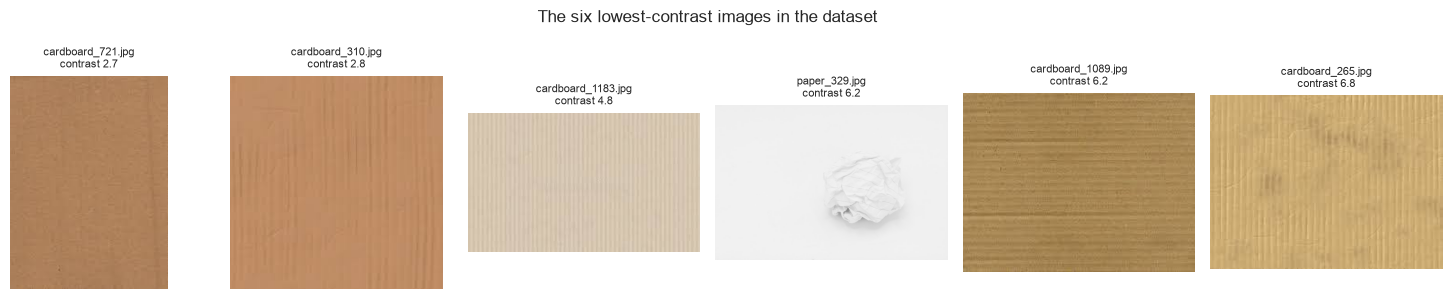

In [6]:
low_contrast = meta.sort_values("contrast").head(6)
small = meta[np.minimum(meta["width"], meta["height"]) < IMG_SIZE]
print("Lowest-contrast images:")
print(low_contrast[["label", "file", "width", "height", "brightness", "contrast"]].round(1).to_string(index=False))
print("---")
print("Images with a short side under", IMG_SIZE, "px:", len(small))
print(small["label"].value_counts().to_string())

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, (_, r) in zip(axes, low_contrast.iterrows()):
    ax.imshow(Image.open(os.path.join(DATA_DIR, "original", r["label"], r["file"])).convert("RGB"))
    ax.set_title(f"{r['file']}\ncontrast {r['contrast']:.1f}", fontsize=8)
    ax.axis("off")
plt.suptitle("The six lowest-contrast images in the dataset")
plt.tight_layout()
plt.show()

### Cleaning decision

The lowest-contrast images are close-ups of corrugated cardboard and a crumpled sheet of paper on white, so they are real pictures of the material, not blank frames. They stay. The 70 small images get enlarged to 128 x 128, which blurs them. Almost half of them are glass (34), so if any class suffers from it, it's glass. But 70 out of 12,259 is 0.6%, too few to change training, so they stay as well.

**Decision:** I drop nothing. All 12,259 images go forward. **What could make me wrong:** "low contrast" only catches flat images. An image of the wrong thing, or a heavily watermarked one, would pass this check, which is why the label checks come next.

## 7. Duplicate and label checks

The paper says exact duplicates and near-duplicates were removed with a perceptual hash at a threshold of 5 [1]. Spark already confirmed there are no exact duplicates left. Near-duplicates are harder: two photos of the same item a second apart, or the same web image saved twice at different sizes, have different bytes but nearly the same picture. If one lands in training and the other in test, the test score looks better than it should.

I use the difference hash (dHash) computed in Spark. I hash the originals rather than the padded 256 versions, because the grey padding bars would dominate the hash of a padded image. I test it in two stages:

1. **Cheap pass:** every image against every other one (about 75 million pairs) on the 64-bit hash. Pairs 5 bits apart or less become candidates.
2. **Strict pass:** for the candidates, a finer 256-bit hash (10 bits apart or less) and the mean pixel difference between 32 x 32 grey thumbnails (8 grey levels or less).

I expect very few pairs to survive, given the authors' cleaning.

In [7]:
# Turn the hex hashes into byte arrays so I can count differing bits with a lookup table

h64 = np.stack([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in meta["dhash64"]])
h256 = np.stack([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in meta["dhash256"]])
thumbs = np.stack([np.frombuffer(t, dtype=np.uint8) for t in meta["thumb32"]]).astype(np.float32)
# bit_count[x] is the number of 1-bits in the byte x. XOR of two hashes, then count bits = how different they are
bit_count = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

# Stage 1: each image against every later image, 64-bit hash
start = time.time()
cand_i, cand_j = [], []
for i in range(len(meta) - 1):
    d = bit_count[np.bitwise_xor(h64[i + 1:], h64[i])].sum(axis=1)
        # Only later images are compared, so each pair is counted once
    js = np.where(d <= 5)[0] + i + 1
    cand_i.extend([i] * len(js))
    cand_j.extend(js.tolist())
cand = pd.DataFrame({"i": cand_i, "j": cand_j})
print("Stage 1 candidate pairs:", len(cand), "| seconds:", round(time.time() - start, 1))

# Stage 2: finer hash and pixel difference, only on the candidates
cand["dist256"] = bit_count[np.bitwise_xor(h256[cand["i"]], h256[cand["j"]])].sum(axis=1)
# Mean difference in grey level (0-255) between the two 32 x 32 thumbnails
cand["pixel_diff"] = np.abs(thumbs[cand["i"]] - thumbs[cand["j"]]).mean(axis=1)
cand["label_i"] = meta["label"].values[cand["i"]]
cand["label_j"] = meta["label"].values[cand["j"]]
cand["same_class"] = cand["label_i"] == cand["label_j"]
cross = (~cand["same_class"]).sum()
print("Stage 1 pairs across two classes:", cross)

# Both conditions must hold. The cut-offs are my choice; the paper used 5 bits on a different hash
twins = cand[(cand["dist256"] <= 10) & (cand["pixel_diff"] <= 8)].copy()
twins["file_i"] = meta["file"].values[twins["i"]]
twins["file_j"] = meta["file"].values[twins["j"]]
print("---")
print("Near-twin pairs after the strict pass:", len(twins),
      "| images involved:", len(set(twins["i"]) | set(twins["j"])),
      "| pairs across classes:", (~twins["same_class"]).sum())
twins.to_csv(os.path.join(ARTIFACTS, "near_twin_pairs.csv"), index=False)

Stage 1 candidate pairs: 41067 | seconds: 1.6
Stage 1 pairs across two classes: 27766
---
Near-twin pairs after the strict pass: 41 | images involved: 49 | pairs across classes: 6


### What the two stages show

The cheap pass flags 41,067 pairs, and 27,766 of them cross two classes. That isn't a sign of mass duplication. A 64-bit hash of a bottle on a white background looks much like the hash of any other bottle on white, so the cheap pass mostly finds similar outlines. The strict pass leaves 41 pairs involving 49 images, 6 of them across classes. A threshold can't tell me which of those are really the same item, so below are the 16 closest pairs to judge by eye.

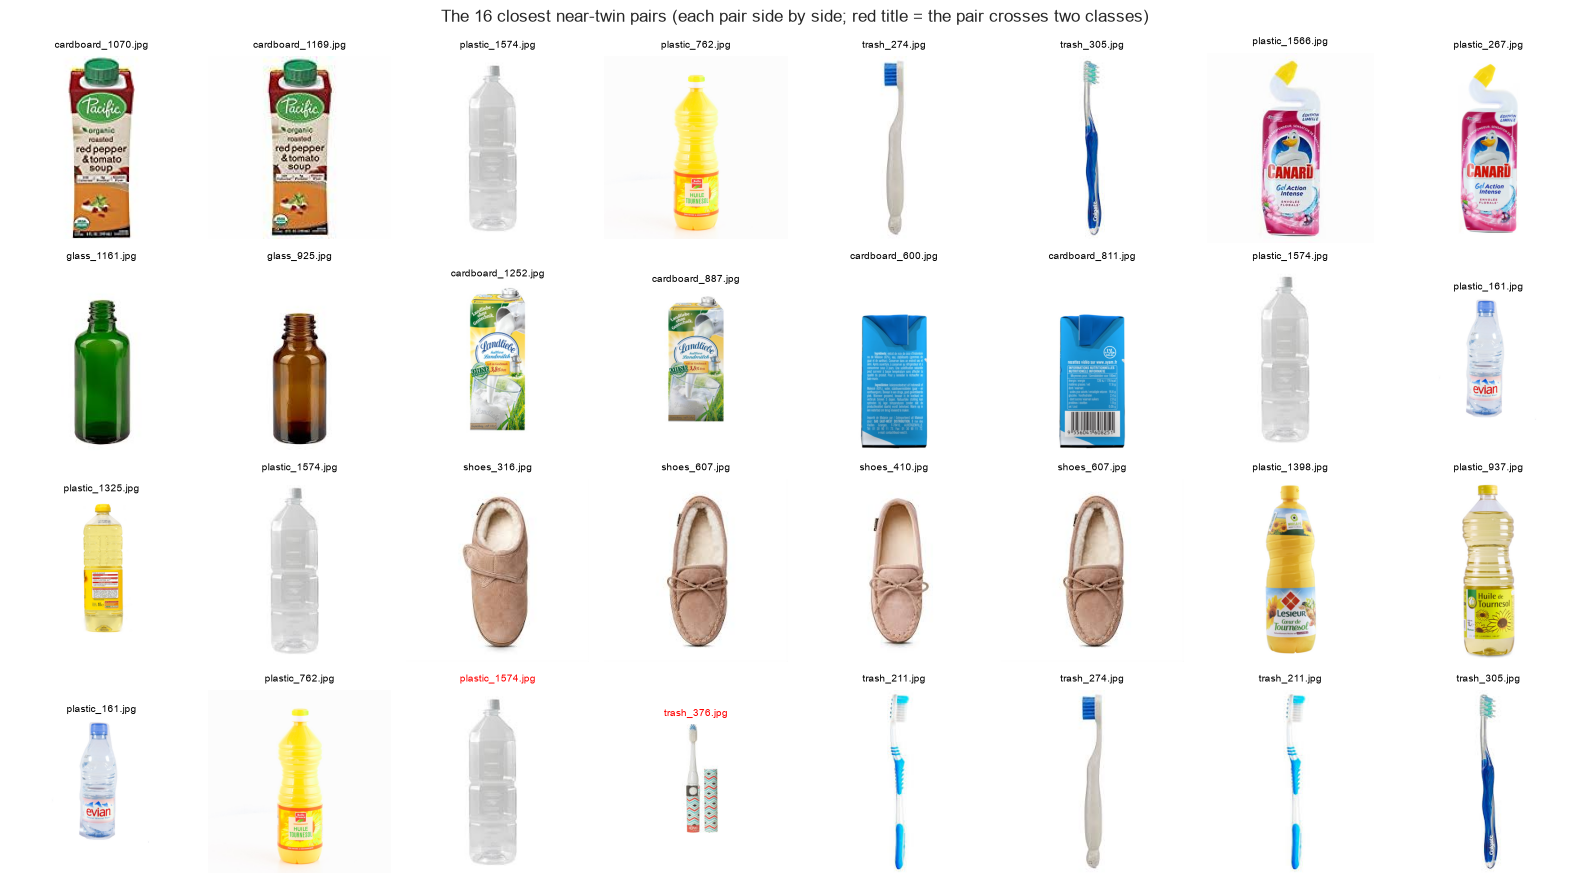

In [8]:
# Each pair takes two neighbouring panels, so 16 pairs fill a 4 x 8 grid
show = twins.sort_values("dist256").head(16)
fig, axes = plt.subplots(4, 8, figsize=(16, 9))
for k, (_, r) in enumerate(show.iterrows()):
    for side, (lab, f) in enumerate([(r["label_i"], r["file_i"]), (r["label_j"], r["file_j"])]):
        ax = axes[k // 4, (k % 4) * 2 + side]
        ax.imshow(Image.open(os.path.join(DATA_DIR, "original", lab, f)).convert("RGB"))
        ax.set_title(f, fontsize=7, color="black" if r["same_class"] else "red")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("The 16 closest near-twin pairs (each pair side by side; red title = the pair crosses two classes)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "near_twin_pairs.png"), dpi=100)
plt.show()

### Duplicate and label check decision

Of the 16 closest pairs, I'd call 6 the same product: the same soup carton (`cardboard_1070`, `cardboard_1169`), the same toilet-cleaner bottle (`plastic_1566`, `plastic_267`), two milk cartons (`cardboard_1252` and `cardboard_887`, `cardboard_600` and `cardboard_811`) and one slipper that appears three times (`shoes_316`, `shoes_410`, `shoes_607`). All 6 are inside one class. The rest are different objects with the same outline on white; one clear plastic bottle, `plastic_1574`, matches five other images on its own because there is so little in it. The one cross-class pair in the figure (`plastic_1574` and `trash_376`) is two different objects, so the hash check gives **no evidence of the same picture carrying two labels.**

So the authors' claim mostly holds. A few same-item pairs are left, which is a leakage risk rather than a labelling one. I don't drop them; instead Section 10 counts how many near-twin pairs end up split across training and test.

**What could make me wrong:** a hash only finds near-identical pictures. Two different photos of the same object from another angle would pass as different, so the real number of same-item pairs is probably higher than this check finds.

### Where do the 512 x 384 images come from?

The Spark summary showed that a lot of images are exactly 512 x 384, all in the six classes TrashNet has, and none in the other four. TrashNet's photos were resized to exactly 512 x 384, and its class counts (paper 594, glass 501, plastic 482, metal 410, cardboard 403, trash 137) [2] are close to the 512 x 384 counts here.

In [9]:
is_512 = (meta["width"] == 512) & (meta["height"] == 384)
# Class counts from the TrashNet README [2]
trashnet_counts = {"paper": 594, "glass": 501, "plastic": 482, "metal": 410, "cardboard": 403, "trash": 137}
compare = pd.DataFrame({"GD images at exactly 512x384": meta[is_512]["label"].value_counts(),
                        "TrashNet images [2]": pd.Series(trashnet_counts)}).fillna(0).astype(int)
compare["GD 512x384 as % of TrashNet"] = (compare.iloc[:, 0] / compare.iloc[:, 1].replace(0, np.nan) * 100).round(1)
print(compare.sort_values("TrashNet images [2]", ascending=False).to_string())
print("---")
print("Total at 512x384:", is_512.sum(), "of", len(meta), f"({is_512.mean() * 100:.1f}%)")

           GD images at exactly 512x384  TrashNet images [2]  GD 512x384 as % of TrashNet
paper                               569                  594                         95.8
glass                               361                  501                         72.1
plastic                             451                  482                         93.6
metal                               399                  410                         97.3
cardboard                           387                  403                         96.0
trash                                51                  137                         37.2
---
Total at 512x384: 2218 of 12259 (18.1%)


### What this tells me

2,218 images (18.1% of the dataset) are exactly 512 x 384. For paper, plastic, metal and cardboard, GD holds between 93.6% and 97.3% as many of them as TrashNet has images in that class; for glass it's 72.1% and for trash 37.2%. None of the battery, biological, clothes or shoes images has this size. I can't prove these are TrashNet images without the TrashNet files, but the exact size, the class pattern and the white backgrounds in the sample grid point that way, and the paper does say 40% of GD came from unnamed public repositories [1]. I treat it as a **likely overlap**, not a fact.

It matters for two reasons. It means about 18% of the images share one studio set-up (white posterboard, indoor light), which a network can latch onto. And it means the "alternative" dataset I rejected is largely already inside this one, so choosing TrashNet would have given me a smaller copy of part of GD.

## 8. Exploratory data analysis

Every plot in this section ends in a decision for the model.

### Class balance

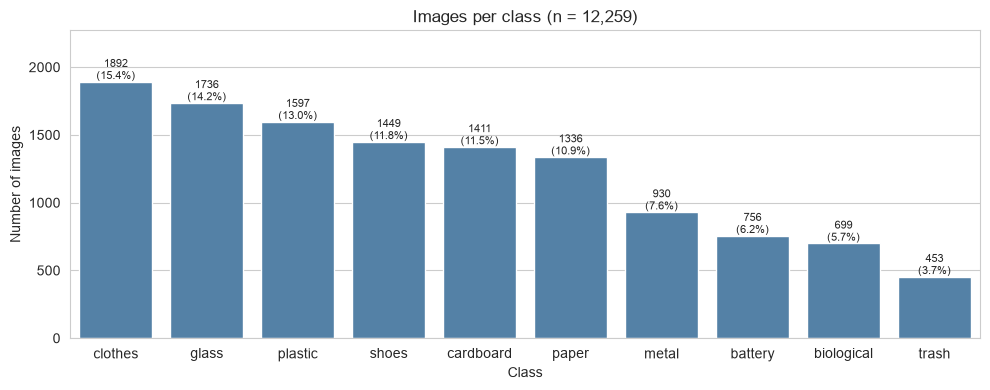

Largest to smallest: 4.18 to 1


In [10]:
# value_counts sorts from largest to smallest, which keeps the bar chart easy to read
counts = meta["label"].value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue", ax=ax)
for k, v in enumerate(counts.values):
        # Count and share written above each bar
    ax.text(k, v + 20, f"{v}\n({v / len(meta) * 100:.1f}%)", ha="center", fontsize=8)
ax.set_title("Images per class (n = 12,259)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_balance.png"), dpi=100)
plt.show()
print("Largest to smallest:", round(counts.max() / counts.min(), 2), "to 1")

### Class balance interpretation

Clothes has 1,892 images (15.4%) and trash 453 (3.7%), a ratio of 4.18 to 1. A model that never predicted trash would lose very little accuracy, so accuracy can't be the main number. **Decisions:** macro F1 as the main metric, a stratified split so each part keeps these shares, and class weights as the first thing to try in the retrain if trash and biological lag. **What could make me wrong:** imbalance is not the only reason a class does badly. Trash is also the most mixed class (masks, toothbrushes, litter), so low trash recall could be about variety rather than numbers, and class weights wouldn't fix that.

### Size, shape and file size by class

The Spark summary suggested that how a photo was taken differs by class. This plot shows it for the whole dataset.

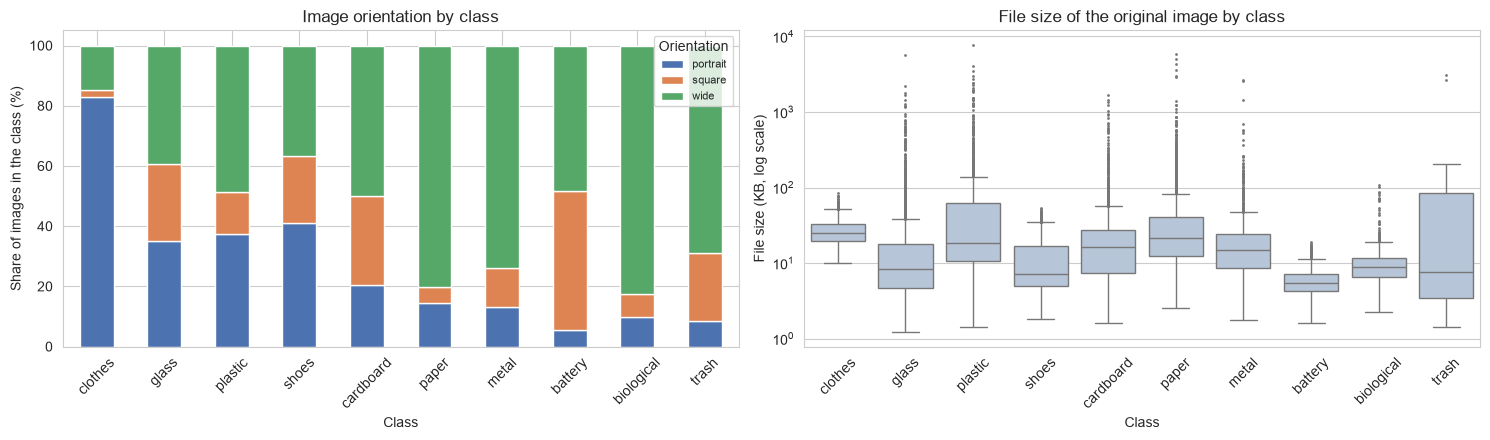

In [11]:
# Three orientation groups from the aspect ratio
meta["orientation"] = np.where(meta["aspect"] < 1, "portrait", np.where(meta["aspect"] == 1, "square", "wide"))
# normalize="index" turns each row into shares of that class, so classes of different sizes compare fairly
orient = pd.crosstab(meta["label"], meta["orientation"], normalize="index") * 100
orient = orient.loc[counts.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
orient.plot(kind="bar", stacked=True, ax=axes[0], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_title("Image orientation by class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Share of images in the class (%)")
axes[0].legend(title="Orientation", fontsize=8)
sns.boxplot(data=meta, x="label", y="kb", order=counts.index, ax=axes[1], color="lightsteelblue", fliersize=1)
# File sizes run from about 1 KB to over 7 MB, so a log scale stops a few huge files flattening the plot
axes[1].set_yscale("log")
axes[1].set_title("File size of the original image by class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("File size (KB, log scale)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "shape_and_size_by_class.png"), dpi=100)
plt.show()

### Size and shape interpretation

The left plot shows that orientation alone separates some classes: most clothes photos are portrait, while battery images are mostly square or wide. The right plot shows the median file size moving by about a factor of four between classes (5.5 KB for battery, 24.8 KB for clothes), on a log scale. None of this is about the material in the photo. It's about where the photo came from: phone photos of clothes on a bed, web product shots of batteries.

**Decision:** this is the strongest reason for the shortcut baseline. I also note that the padded 256 version turns orientation into pixels the CNN can see (grey bars at the sides for portrait photos, at the top and bottom for wide ones), so the CNN can pick up this cue too. I can't remove the bars without cropping the objects, so instead I measure how much the cue is worth and keep it in mind when reading the CNN's results. **What could make me wrong:** some of the difference may be real. Clothes are taller than they are wide, so portrait framing is partly a property of the object, not only of the source.

### Brightness

The paper reports brightness skewed towards over-exposure [1]. My measure is simpler (the mean grey level of each original image), so I check the spread per class rather than compare numbers with theirs.

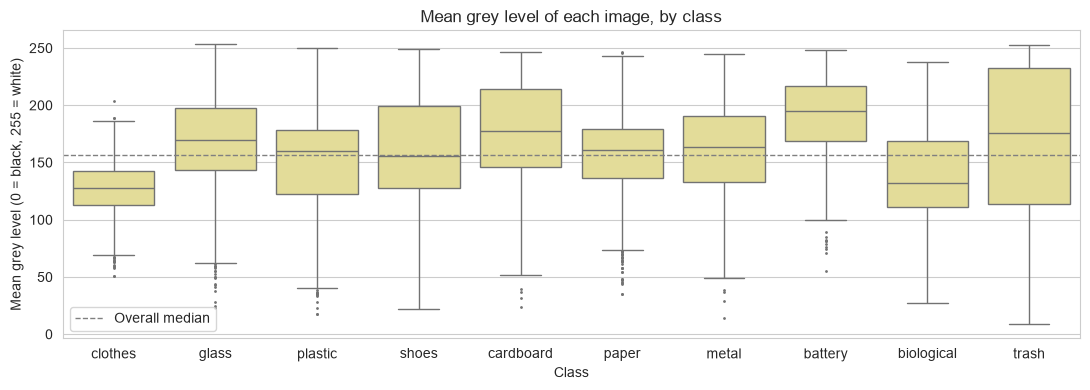

Overall mean: 158.2 | sd: 43.9 | share above 200: 19.5% | share below 60: 1.0%
label
clothes       127.3
biological    132.3
shoes         155.5
plastic       159.6
paper         161.2
metal         163.2
glass         170.0
trash         176.1
cardboard     177.1
battery       195.2


In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=meta, x="label", y="brightness", order=counts.index, color="khaki", fliersize=1, ax=ax)
# The dashed line makes it easy to see which classes sit above or below the dataset as a whole
ax.axhline(meta["brightness"].median(), color="grey", linestyle="--", linewidth=1, label="Overall median")
ax.set_title("Mean grey level of each image, by class")
ax.set_xlabel("Class")
ax.set_ylabel("Mean grey level (0 = black, 255 = white)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "brightness_by_class.png"), dpi=100)
plt.show()
print("Overall mean:", round(meta["brightness"].mean(), 1), "| sd:", round(meta["brightness"].std(), 1),
      "| share above 200:", f"{(meta['brightness'] > 200).mean() * 100:.1f}%",
      "| share below 60:", f"{(meta['brightness'] < 60).mean() * 100:.1f}%")
print(meta.groupby("label")["brightness"].median().round(1).sort_values().to_string())

### Brightness interpretation

The overall mean grey level is 158.2 out of 255, and 19.5% of images have a mean above 200, while only 1.0% are below 60. Battery images are the brightest (median 195.2), which fits product shots on white, and clothes and biological the darkest. So the dataset leans bright, and dark photos, like the inside of a bin, are rare.

**Decisions:** random brightness changes of up to 20% during training, so the network doesn't tie "bright" to "battery"; and darker and brighter versions of the test set in the stress tests (Section 15), because a dark bin is exactly the condition the training data is short of. **What could make me wrong:** mean grey level mixes object and background. A white product on white and a dark product on white can have similar means, so this measure says more about backgrounds than about exposure.

### What the images look like

Six random images per class from the padded 256 version, the version the model sees.

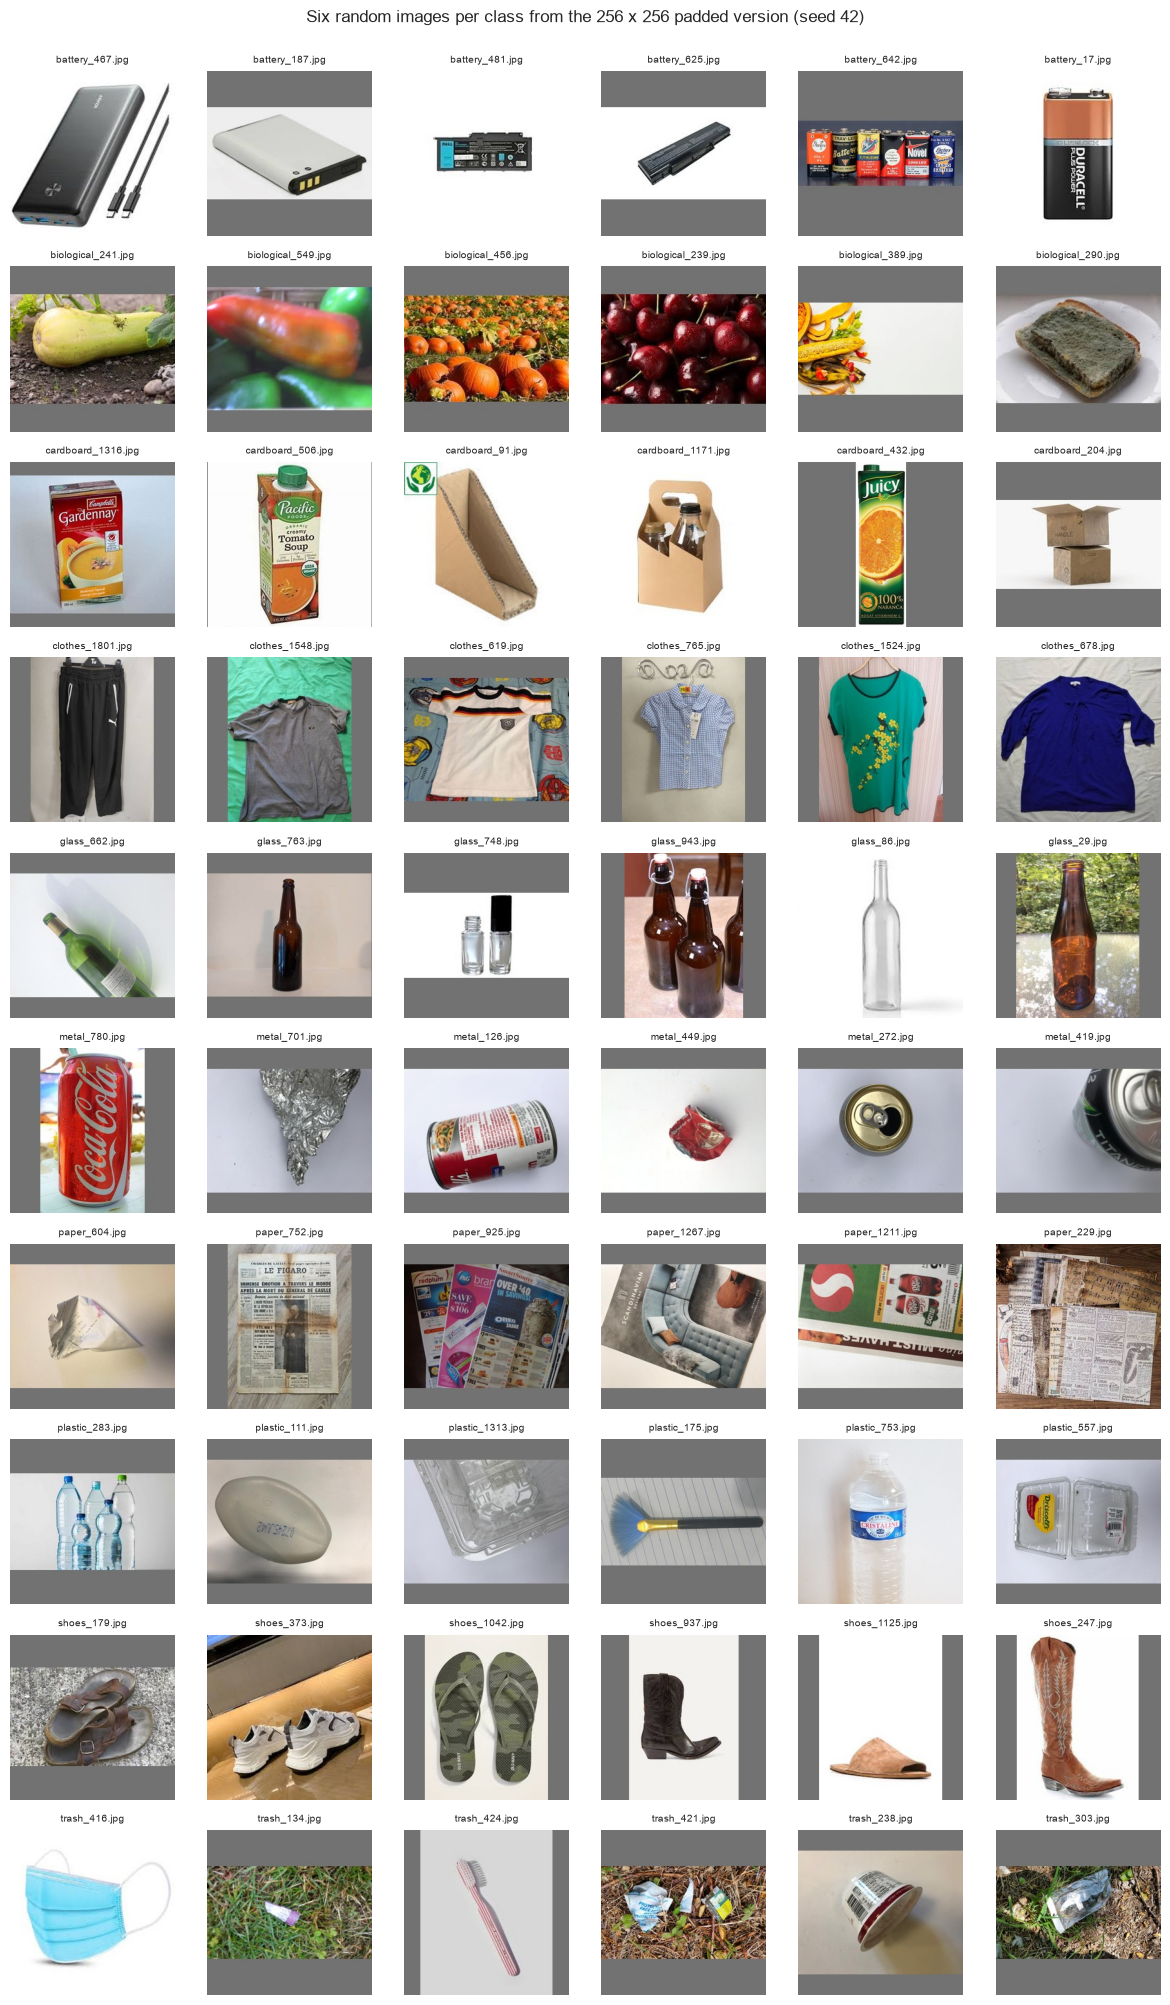

In [13]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 20))
for r, c in enumerate(CLASSES):
        # The same seed gives the same six images every run
    sample = meta[meta["label"] == c].sample(6, random_state=SEED)
    for k, f in enumerate(sample["file"]):
        axes[r, k].imshow(Image.open(os.path.join(DATA_DIR, "standardized_256", c, f)))
        axes[r, k].set_title(f, fontsize=7)
        axes[r, k].axis("off")
plt.suptitle("Six random images per class from the 256 x 256 padded version (seed 42)", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sample_grid.png"), dpi=80)
plt.show()

### What I see in the samples

The grey padding bars are on almost every image. Battery is mostly product shots on white. Biological is often fresh produce rather than food waste. Several cardboard images are drink and soup cartons, which are a mix of board, plastic and foil and go into a separate stream in many recycling schemes. Trash is a mix of masks, toothbrushes and litter photographed outdoors on grass or soil, so ground is a background cue for that class.

**Decision:** I keep the labels as given and test them properly through the model's mistakes in Section 16. The carton question goes into the business section, because it's a decision for the press: do cartons belong with cardboard at their premises or not?

### EDA summary

What I now know: the data is clean (nothing broken, no exact copies, a handful of near-copies), moderately imbalanced (4.18 to 1), bright on average, and the way a photo was taken differs by class, partly because about 2,200 images look like they come from one studio dataset. What I decided: stratified split, macro F1, brightness augmentation, a shortcut baseline, and stress tests aimed at dark and low-quality photos. What carries forward: every CNN result has to be read against the shortcut baseline.

## 9. What feature selection means for a CNN

In Part 2 feature selection meant dropping columns with p-values. A CNN doesn't take columns. Its first layers learn small filters (edges, corners, textures) and later layers combine them into larger patterns, so the features are learned from the pixels during training. What I control is what the network gets to see:

- **Input size, 128 x 128.** At 128 the whole dataset is 0.60 GB as whole numbers (0 to 255), which fits on an 8 GB laptop, and only 70 images have to be enlarged. 256 would quadruple memory and training time.
- **Colour, RGB.** Green and brown glass, brown cardboard and printed packaging all carry colour information that grey images would throw away.
- **Scaling, divide by 255 inside the model.** The network trains better on values between 0 and 1. Doing the division in the first layer keeps the stored arrays four times smaller than converting them all to decimals first.
- **Augmentation, training only.** Random horizontal flips, rotations of up to about 14 degrees, zoom of up to 10% and brightness changes of up to 20%. Each is tied to something above: objects lie at any angle, they fill very different amounts of the frame, and the data leans bright. I don't flip vertically or shift colours, because upside-down shoes are rare and colour is a real signal.

The shortcut baseline in Section 11 is the nearest thing to classic feature selection here: it checks whether five features that say nothing about the material already predict the class.

## 10. Preprocessing, split and augmentation

### Loading the pixels

I load each padded 256 image with Pillow, shrink it to 128 x 128 and keep it as 8-bit whole numbers (`uint8`). I expect an array of shape (12259, 128, 128, 3) taking about 0.6 GB.

In [14]:
start = time.time()
# I fill a pre-made uint8 array instead of building a list, so memory never doubles while loading
X = np.zeros((len(meta), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
for k, (lab, f) in enumerate(zip(meta["label"], meta["file"])):
    img = Image.open(os.path.join(DATA_DIR, "standardized_256", lab, f)).convert("RGB")
        # Bilinear resizing averages neighbouring pixels, which shrinks the image without jagged edges
    X[k] = np.asarray(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
y = meta["y"].to_numpy()
print("X:", X.shape, X.dtype, f"{X.nbytes / 1e9:.2f} GB", "| seconds:", round(time.time() - start, 1))

X: (12259, 128, 128, 3) uint8 0.60 GB | seconds: 18.9


The array is the size I expected. Before splitting I look at the average image of each class. If the network can learn a class from its average image alone, the information is in the framing rather than the object.

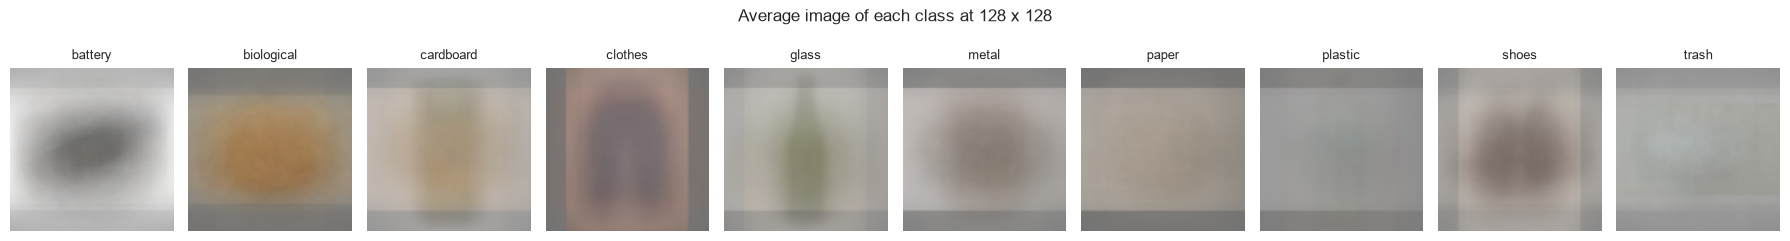

In [15]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(18, 2.6))
for k, c in enumerate(CLASSES):
        # Average every image of the class pixel by pixel
    axes[k].imshow(X[y == k].mean(axis=0).astype(np.uint8))
    axes[k].set_title(c, fontsize=9)
    axes[k].axis("off")
plt.suptitle("Average image of each class at 128 x 128")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "mean_image_per_class.png"), dpi=100)
plt.show()

### Mean image interpretation

This plot shows two kinds of signal at once. Some of it is real: the biological average is orange, the glass average is a green bottle, the battery average is a dark blob on white and the clothes average has the outline of a pair of trousers. Some of it isn't: the grey padding bars are clearly visible, at the sides for clothes and shoes (portrait photos) and at the top and bottom for most other classes. The network will see both, and nothing in its training tells it that the bars don't count.

**Decision:** I keep the padded images, because cropping the bars off would cut into the objects, and I rely on the shortcut baseline and the stress tests to tell me how much the framing is worth. **What could make me wrong:** an average image hides variety. A class can have a clear average and still contain very different-looking items, as trash does.

### The split

Stratified 70/15/15 with seed 42. Stratified means each part keeps the same class shares. I split twice: 70% for training and 30% held back, then the held-back part in half for validation and test. Validation is used to stop training and to choose between models; the test set is touched only for the final numbers.

In [16]:
idx = np.arange(len(meta))
# I split image positions (indices), not the images, so I can trace any image back to its file later
idx_train, idx_hold = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
# Half of the 30% becomes validation and half test, again keeping class shares
idx_val, idx_test = train_test_split(idx_hold, test_size=0.50, stratify=y[idx_hold], random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]

split = np.empty(len(meta), dtype=object)
split[idx_train], split[idx_val], split[idx_test] = "train", "val", "test"
meta["split"] = split
# Saved so the exact split can be checked or reused later
meta[["label", "file", "split"]].to_csv(os.path.join(ARTIFACTS, "split.csv"), index=False)

print("Train:", len(idx_train), "| validation:", len(idx_val), "| test:", len(idx_test))
print("---")
print(pd.crosstab(meta["label"], meta["split"])[["train", "val", "test"]].to_string())

Train: 8581 | validation: 1839 | test: 1839
---
split       train  val  test
label                       
battery       529  114   113
biological    489  105   105
cardboard     988  212   211
clothes      1325  283   284
glass        1215  260   261
metal         651  139   140
paper         935  201   200
plastic      1118  239   240
shoes        1014  218   217
trash         317   68    68


### Split interpretation

The split gives 8,581 training, 1,839 validation and 1,839 test images, with every class in the same proportion in each part. Trash has only 68 test images, so one extra mistake in trash moves its recall by about 1.5 points. That's why I put intervals around the per-class numbers later.

### Leak check

Now I check whether any near-twin pairs from Section 7 were split across the parts.

In [17]:
# Which part each image of a near-twin pair ended up in
twins["split_i"] = meta["split"].values[twins["i"]]
twins["split_j"] = meta["split"].values[twins["j"]]
crossing = twins[twins["split_i"] != twins["split_j"]]
print("Near-twin pairs:", len(twins), "| split across two parts:", len(crossing))
print(crossing.groupby(["split_i", "split_j"]).size().to_string() if len(crossing) else "none")
test_with_twin_in_train = set(crossing.loc[(crossing["split_i"] == "test") & (crossing["split_j"] == "train"), "i"]) | \
                          set(crossing.loc[(crossing["split_j"] == "test") & (crossing["split_i"] == "train"), "j"])
print("Test images with a near-twin in training:", len(test_with_twin_in_train), "of", len(idx_test))

Near-twin pairs: 41 | split across two parts: 22
split_i  split_j
test     train      2
train    test       3
         val        9
val      test       1
         train      7
Test images with a near-twin in training: 5 of 1839


### Leak check interpretation

22 of the 41 near-twin pairs ended up in two different parts, and 5 test images have a near-twin in the training set. That's 5 of 1,839 test images (0.3%). Even if the model got all 5 right only because it had seen the twin, the test accuracy would move by at most 0.3 points, which is far smaller than the bootstrap intervals I'll report.

**Decision:** keep the split as it is and mention the 5 in the limitations. **What could make me wrong:** the hash only catches near-identical pictures, so the true number of related images across the split is higher than 5.

### Augmentation

These layers sit at the front of the CNN, so they only change images during training. Keras switches them off when the model predicts, which means validation and test images are never altered. Below is one training image passed through them six times, to check the changes look realistic and not destructive.

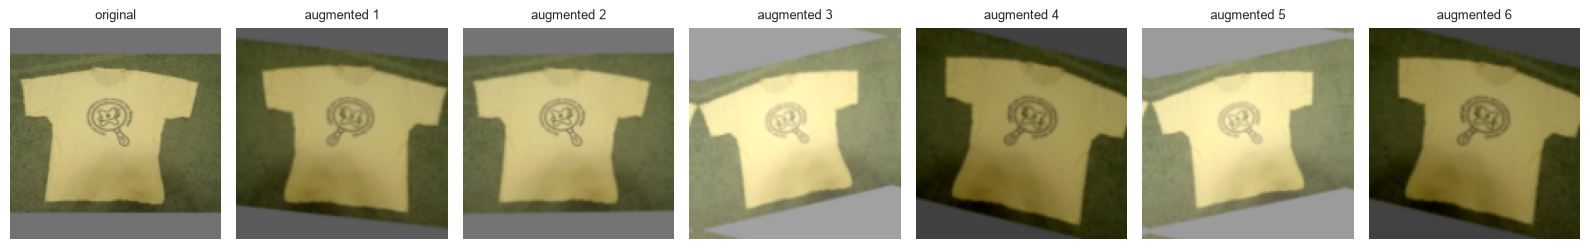

In [18]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    # 0.04 of a full turn is about 14 degrees either way
    layers.RandomRotation(0.04, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
    # Values are still 0-255 at this point, which is RandomBrightness's default range
    layers.RandomBrightness(0.2, seed=SEED),
], name="augmentation")

# training=True forces the random layers on, so I can see what the network will see
example = X_train[:1].astype("float32")
fig, axes = plt.subplots(1, 7, figsize=(16, 2.6))
axes[0].imshow(example[0].astype(np.uint8))
axes[0].set_title("original", fontsize=9)
for k in range(1, 7):
    out = augment(example, training=True).numpy()[0]
    axes[k].imshow(np.clip(out, 0, 255).astype(np.uint8))
    axes[k].set_title(f"augmented {k}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The six copies are still clearly the same T-shirt, a bit turned, zoomed or darker, which is the point: the class shouldn't change. One side effect is visible in copies 3 and 5: when the image turns, Keras fills the empty corners by mirroring the edge, so a lighter grey wedge of mirrored padding appears. It's a small, random artefact and it doesn't line up with any class, so I accept it.

### Section 10 summary

The images are in memory as a 0.60 GB array, split 70/15/15 by class, with the near-twin leak measured. **Decision:** go ahead with this split and these augmentations. **What could make me wrong:** a random split mixes sources, so the same studio set-up (the probable TrashNet images) appears in training and test. The test score measures how well the model does on photos like the ones it trained on, not on a new camera or a new bin.

## 11. Baselines

### Majority class

The simplest possible model always predicts the biggest class. It sets the floor.

In [19]:
# Small helper so every model is scored the same way
def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro")}


# The dummy model ignores its input, so a column of zeros is enough
majority = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
pred_major_val = majority.predict(np.zeros((len(y_val), 1)))
pred_major_test = majority.predict(np.zeros((len(y_test), 1)))
results = {"Majority class": {"val": scores(y_val, pred_major_val), "test": scores(y_test, pred_major_test)}}
print("Always predicts:", CLASSES[pred_major_val[0]])
print("Validation:", {k: round(v, 4) for k, v in results["Majority class"]["val"].items()})

Always predicts: clothes
Validation: {'accuracy': 0.1539, 'macro_f1': 0.0267}


Always guessing clothes gets 15.4% accuracy and a macro F1 of 0.027 on validation, because it scores zero on nine of the ten classes. Any real model has to clear this easily.

### The shortcut model

This model never sees a pixel. It gets five numbers per image: width, height, aspect ratio, mean brightness and file size, all from the Spark metadata. I use a random forest because it handles features on different scales and picks up thresholds like "exactly 512 wide" without any tuning. If it scores far above the majority class, those five numbers carry class information that has nothing to do with the material [3].

In [20]:
shortcut_cols = ["width", "height", "aspect", "brightness", "kb"]
# Five numbers per image and nothing about what the object is
S = meta[shortcut_cols].to_numpy()
# 300 trees is plenty for five features; n_jobs=-1 uses every CPU core
forest = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
forest.fit(S[idx_train], y_train)
pred_forest_val = forest.predict(S[idx_val])
pred_forest_test = forest.predict(S[idx_test])
results["Shortcut forest"] = {"val": scores(y_val, pred_forest_val), "test": scores(y_test, pred_forest_test)}
np.save(os.path.join(ARTIFACTS, "pred_shortcut_test.npy"), pred_forest_test)

print("Validation:", {k: round(v, 4) for k, v in results["Shortcut forest"]["val"].items()})
print("---")
# How much each feature helped the trees split the classes (they sum to 1)
print(pd.Series(forest.feature_importances_, index=shortcut_cols).sort_values(ascending=False).round(3).to_string())
print("---")
print(classification_report(y_val, pred_forest_val, target_names=CLASSES, digits=3))

Validation: {'accuracy': 0.4802, 'macro_f1': 0.44}
---
kb            0.302
brightness    0.296
width         0.148
height        0.146
aspect        0.108
---
              precision    recall  f1-score   support

     battery      0.308     0.281     0.294       114
  biological      0.391     0.495     0.437       105
   cardboard      0.437     0.443     0.440       212
     clothes      0.824     0.912     0.866       283
       glass      0.383     0.377     0.380       260
       metal      0.304     0.201     0.242       139
       paper      0.545     0.597     0.570       201
     plastic      0.460     0.452     0.456       239
       shoes      0.315     0.317     0.316       218
       trash      0.462     0.353     0.400        68

    accuracy                          0.480      1839
   macro avg      0.443     0.443     0.440      1839
weighted avg      0.470     0.480     0.473      1839



### Shortcut model interpretation

This is the most important baseline in the notebook. Without seeing a single pixel, the forest reaches a validation macro F1 of **0.440** and accuracy of 48.0%, against 0.027 for always guessing clothes. File size (importance 0.302) and brightness (0.296) carry most of it, then width and height. It finds 91.2% of clothes images from these five numbers alone (F1 0.866), and does worst on metal (recall 0.201) and battery (F1 0.294).

So the way a photo was taken predicts its class far better than chance. That doesn't prove the CNN will use these cues, but it means it can, and nothing in a plain accuracy figure would tell me. The strongest alternative explanation is that some of this is real content rather than source: a crumpled pile of clothes on a patterned bed makes a bigger JPEG than a single battery on white, and clothes really are taller than wide. File size mixes both, and I can't separate them with this data.

**Decision:** the CNN has to beat 0.440 clearly, and when I read its per-class results I'll be most careful with clothes, where the forest alone already does very well. If the CNN's advantage over the forest is small for a class, I can't claim it has learnt the material. **What could make me wrong:** a random forest on five numbers is a weak model; a stronger one (or more metadata) might get even more out of the framing, so 0.440 is a lower bound on how much the shortcut is worth.

### Dense network on raw pixels

The last baseline is a plain neural network with no convolution. It shrinks each image to 32 x 32, flattens it into 3,072 numbers and passes them through one hidden layer. If the CNN can't beat this, the convolution layers aren't adding much. It uses the same early stopping as the CNN, and it saves itself so it's never retrained by accident.

In [21]:
# Early stopping watches validation loss and keeps the weights from the best epoch
def callbacks_for(name):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
            keras.callbacks.ModelCheckpoint(os.path.join(ARTIFACTS, f"{name}.keras"), monitor="val_loss", save_best_only=True)]


# Trains the model, or loads the saved one if it exists and RETRAIN is False
def train_or_load(name, build_fn, class_weight=None):
    path = os.path.join(ARTIFACTS, f"{name}.keras")
    hist_path = os.path.join(ARTIFACTS, f"history_{name}.json")
        # This is what stops a long training run from being repeated by accident
    if os.path.exists(path) and not RETRAIN:
        print(f"Loading saved {name} (set RETRAIN = True to train again)")
        return keras.models.load_model(path), json.load(open(hist_path))
        # Re-seed before every model so each one starts from the same random state
    keras.utils.set_random_seed(SEED)
    model = build_fn()
    start = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
                  callbacks=callbacks_for(name), class_weight=class_weight, verbose=2)
        # Keras history holds numpy numbers, which json can't save, so I convert them to plain floats
    history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    history["seconds"] = time.time() - start
    history["seed"] = SEED
    json.dump(history, open(hist_path, "w"))
    model.save(path)
    print(f"{name}: {len(history['loss'])} epochs in {history['seconds'] / 60:.1f} minutes")
    return model, history


def build_dense():
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
                # 32 x 32 keeps the dense layer to about 790,000 weights; at 128 x 128 it would be over 12 million
        layers.Resizing(32, 32),
        layers.Rescaling(1.0 / 255),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(CLASSES), activation="softmax"),
    ], name="dense_baseline")


# SMOKE-HOOK
dense_model = build_dense()
dense_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Dense baseline parameters:", f"{dense_model.count_params():,}")

Dense baseline parameters: 789,258


In [22]:
def build_dense_compiled():
    m = build_dense()
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


dense_model, dense_hist = train_or_load("dense_baseline", build_dense_compiled)
prob_dense_val = dense_model.predict(X_val, verbose=0)
prob_dense_test = dense_model.predict(X_test, verbose=0)
np.save(os.path.join(ARTIFACTS, "prob_dense_val.npy"), prob_dense_val)
np.save(os.path.join(ARTIFACTS, "prob_dense_test.npy"), prob_dense_test)
results["Dense network"] = {"val": scores(y_val, prob_dense_val.argmax(1)), "test": scores(y_test, prob_dense_test.argmax(1))}
print("Validation:", {k: round(v, 4) for k, v in results["Dense network"]["val"].items()})

Epoch 1/30
269/269 - 2s - 6ms/step - accuracy: 0.1996 - loss: 2.2059 - val_accuracy: 0.2795 - val_loss: 1.9886
Epoch 2/30
269/269 - 1s - 3ms/step - accuracy: 0.2627 - loss: 2.0068 - val_accuracy: 0.3643 - val_loss: 1.8830
Epoch 3/30
269/269 - 1s - 3ms/step - accuracy: 0.2841 - loss: 1.9543 - val_accuracy: 0.3393 - val_loss: 1.8994
Epoch 4/30
269/269 - 1s - 3ms/step - accuracy: 0.2869 - loss: 1.9262 - val_accuracy: 0.3415 - val_loss: 1.8365
Epoch 5/30
269/269 - 1s - 3ms/step - accuracy: 0.2930 - loss: 1.9308 - val_accuracy: 0.3518 - val_loss: 1.8397
Epoch 6/30
269/269 - 1s - 3ms/step - accuracy: 0.3033 - loss: 1.8800 - val_accuracy: 0.3801 - val_loss: 1.7937
Epoch 7/30
269/269 - 1s - 3ms/step - accuracy: 0.3018 - loss: 1.8826 - val_accuracy: 0.3725 - val_loss: 1.7932
Epoch 8/30
269/269 - 1s - 3ms/step - accuracy: 0.3046 - loss: 1.8718 - val_accuracy: 0.3801 - val_loss: 1.7842
Epoch 9/30
269/269 - 1s - 3ms/step - accuracy: 0.3157 - loss: 1.8537 - val_accuracy: 0.3817 - val_loss: 1.7689
E

### Dense baseline interpretation

The dense network reaches a validation macro F1 of 0.331 and accuracy of 39.5%, and early stopping ended it after 25 of the 30 epochs. That's far above the majority class, but **below the shortcut forest (0.440)**. A network that sees every pixel of a 32 x 32 thumbnail does worse than a forest that sees five numbers about the file.

I read that two ways. Shrinking to 32 x 32 throws away most of the texture that separates paper from cardboard or glass from plastic, and without convolution the network has to learn each pixel position on its own, so a pattern it learns in one corner doesn't help it anywhere else. It also confirms how much the file-level information is worth: those five numbers carry more class information than a tiny thumbnail does.

**Decision:** the bar for the CNN is the shortcut forest, not the dense network. **What could make me wrong:** a bigger dense network at 64 x 64 might do better. I kept it small so it trains in seconds, so 0.331 is a floor for "pixels without convolution", not a ceiling.

### Section 11 summary

On validation macro F1 the baselines rank majority class 0.027, dense network 0.331, shortcut forest 0.440. The shortcut forest is the real bar. If the CNN only matched it, I couldn't say it had learnt anything about materials.

## 12. CNN v1

### Architecture, and why each layer is there

| Layer | Setting | Why |
|---|---|---|
| Augmentation | flip, rotate, zoom, brightness (Section 10) | Only active in training; teaches the network that these changes don't change the class |
| Rescaling | divide by 255 | Values between 0 and 1 train more smoothly than 0 to 255 |
| Conv block 1 | 32 filters, 3 x 3, ReLU, then 2 x 2 max-pooling | Learns small patterns such as edges; pooling halves the image to 64 x 64 and keeps the strongest response in each patch |
| Conv block 2 | 64 filters, 3 x 3, ReLU, max-pool | Combines edges into textures and parts (corrugation, labels, rims); 32 x 32 after pooling |
| Conv block 3 | 128 filters, 3 x 3, ReLU, max-pool | Larger shapes; 16 x 16 after pooling. Doubling the filters as the image halves keeps the work per layer roughly even |
| Global average pooling | one number per filter | Averages each of the 128 maps into one value. Far fewer weights than flattening (128 instead of 32,768 inputs to the next layer), so less room to memorise |
| Dense | 128 units, ReLU | Combines the 128 pattern scores into class evidence |
| Dropout | 0.4 | Switches off 40% of these units at random in each training step, so the network can't rely on a few of them [6] |
| Output | 10 units, softmax | One probability per class, summing to 1 |

Loss is sparse categorical cross-entropy (the labels are whole numbers 0 to 9). The optimiser is Adam with a learning rate of 0.001, the default its authors suggest [5]. The lecturer's MNIST example uses two convolution layers, Flatten and Dense; I added pooling, dropout, global average pooling and augmentation because these images are bigger, more varied and far fewer per class than MNIST's.

In [23]:
def build_cnn():
    model = keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.04, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
        layers.RandomBrightness(0.2, seed=SEED),
                # padding="same" keeps the image size through each convolution; pooling does the shrinking
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(len(CLASSES), activation="softmax"),
    ], name="cnn")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


build_cnn().summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 128, 128, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

### Parameter count

The model has 111,050 trainable weights, against 8,581 training images. Most of them sit in the third convolution block. It's small on purpose: it trains on a laptop CPU, and a small network has less room to memorise the training images.

One limit I need to be upfront about: I train each network **once, with one seed**. A second run with a different seed would give slightly different weights and scores, so a small gap between two of my models could be training noise rather than a real difference. McNemar's test (Section 13) only covers the noise from which images happen to be in the test set, not this.

In [24]:
cnn_v1, hist_v1 = train_or_load("cnn_v1", build_cnn)
# predict gives one probability per class; argmax later picks the most likely class
prob_v1_val = cnn_v1.predict(X_val, verbose=0)
prob_v1_test = cnn_v1.predict(X_test, verbose=0)
np.save(os.path.join(ARTIFACTS, "prob_cnn_v1_val.npy"), prob_v1_val)
np.save(os.path.join(ARTIFACTS, "prob_cnn_v1_test.npy"), prob_v1_test)
np.save(os.path.join(ARTIFACTS, "y_val.npy"), y_val)
np.save(os.path.join(ARTIFACTS, "y_test.npy"), y_test)
open(os.path.join(ARTIFACTS, "seed.txt"), "w").write(str(SEED))
results["CNN v1"] = {"val": scores(y_val, prob_v1_val.argmax(1)), "test": scores(y_test, prob_v1_test.argmax(1))}
print("Epochs run:", len(hist_v1["loss"]), "| best epoch:", int(np.argmin(hist_v1["val_loss"])) + 1)
print("Validation:", {k: round(v, 4) for k, v in results["CNN v1"]["val"].items()})

Epoch 1/30
269/269 - 43s - 160ms/step - accuracy: 0.1971 - loss: 2.1815 - val_accuracy: 0.2974 - val_loss: 2.0382
Epoch 2/30
269/269 - 43s - 159ms/step - accuracy: 0.2778 - loss: 2.0163 - val_accuracy: 0.2724 - val_loss: 1.9525
Epoch 3/30
269/269 - 41s - 153ms/step - accuracy: 0.3413 - loss: 1.8515 - val_accuracy: 0.3741 - val_loss: 1.7802
Epoch 4/30
269/269 - 40s - 149ms/step - accuracy: 0.3914 - loss: 1.7292 - val_accuracy: 0.4171 - val_loss: 1.6505
Epoch 5/30
269/269 - 40s - 149ms/step - accuracy: 0.4185 - loss: 1.6667 - val_accuracy: 0.4084 - val_loss: 1.6831
Epoch 6/30
269/269 - 40s - 148ms/step - accuracy: 0.4241 - loss: 1.6352 - val_accuracy: 0.4307 - val_loss: 1.6080
Epoch 7/30
269/269 - 43s - 162ms/step - accuracy: 0.4384 - loss: 1.5921 - val_accuracy: 0.4345 - val_loss: 1.5858
Epoch 8/30
269/269 - 43s - 161ms/step - accuracy: 0.4489 - loss: 1.5616 - val_accuracy: 0.4611 - val_loss: 1.5279
Epoch 9/30
269/269 - 42s - 155ms/step - accuracy: 0.4601 - loss: 1.5382 - val_accuracy: 

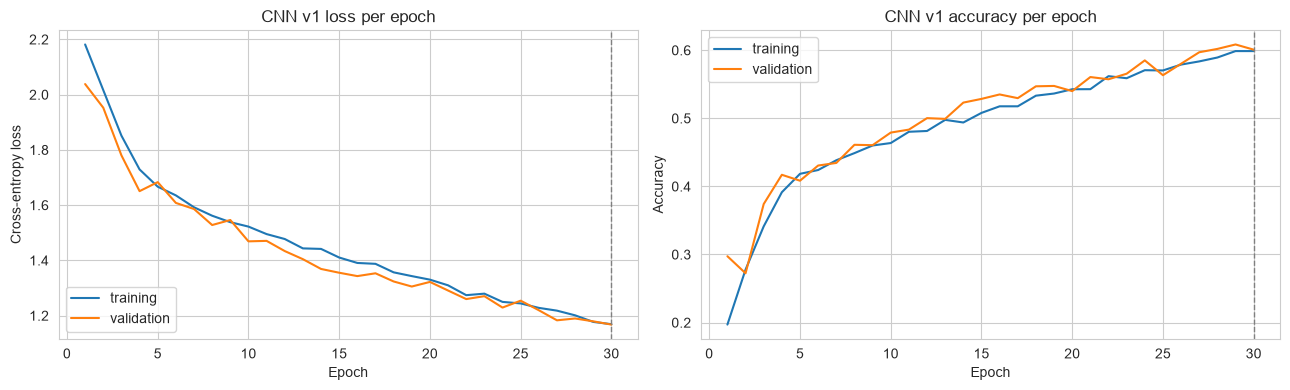

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# The dashed line marks the epoch with the lowest validation loss, which is the one early stopping kept
ep = np.arange(1, len(hist_v1["loss"]) + 1)
axes[0].plot(ep, hist_v1["loss"], label="training")
axes[0].plot(ep, hist_v1["val_loss"], label="validation")
axes[0].set_title("CNN v1 loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].plot(ep, hist_v1["accuracy"], label="training")
axes[1].plot(ep, hist_v1["val_accuracy"], label="validation")
axes[1].set_title("CNN v1 accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.axvline(int(np.argmin(hist_v1["val_loss"])) + 1, color="grey", linestyle="--", linewidth=1)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "learning_curves_cnn_v1.png"), dpi=100)
plt.show()

### Learning curves interpretation

Both curves are still going down at epoch 30, and early stopping never fired: the lowest validation loss (1.1675) came in the very last epoch. Training and validation stay close the whole way (at epoch 30, 59.9% training accuracy against 60.1% validation), so there is no sign of overfitting. Validation is even slightly ahead for much of the run. That's what I'd expect, because augmentation and dropout make training harder and both are switched off when the model predicts validation images.

So v1 is **underfitted, not overfitted**: it ran out of epochs before it ran out of things to learn. That's one of its shortcomings, and I come back to it in Section 14. **What could make me wrong:** curves this smooth can still flatten soon after, so without running longer I can't say how much there was left to gain. Training took 44.5 minutes, which is why I didn't simply double the epochs.

## 13. Evaluating CNN v1

First the per-class report on the **validation** set, because validation is what I use to judge and change the model. The test set waits until I've chosen.

              precision    recall  f1-score   support

     battery      0.669     0.728     0.697       114
  biological      0.685     0.724     0.704       105
   cardboard      0.636     0.774     0.698       212
     clothes      0.692     0.827     0.754       283
       glass      0.709     0.600     0.650       260
       metal      0.457     0.230     0.306       139
       paper      0.405     0.687     0.509       201
     plastic      0.663     0.469     0.549       239
       shoes      0.513     0.459     0.484       218
       trash      0.769     0.147     0.247        68

    accuracy                          0.601      1839
   macro avg      0.620     0.564     0.560      1839
weighted avg      0.615     0.601     0.588      1839



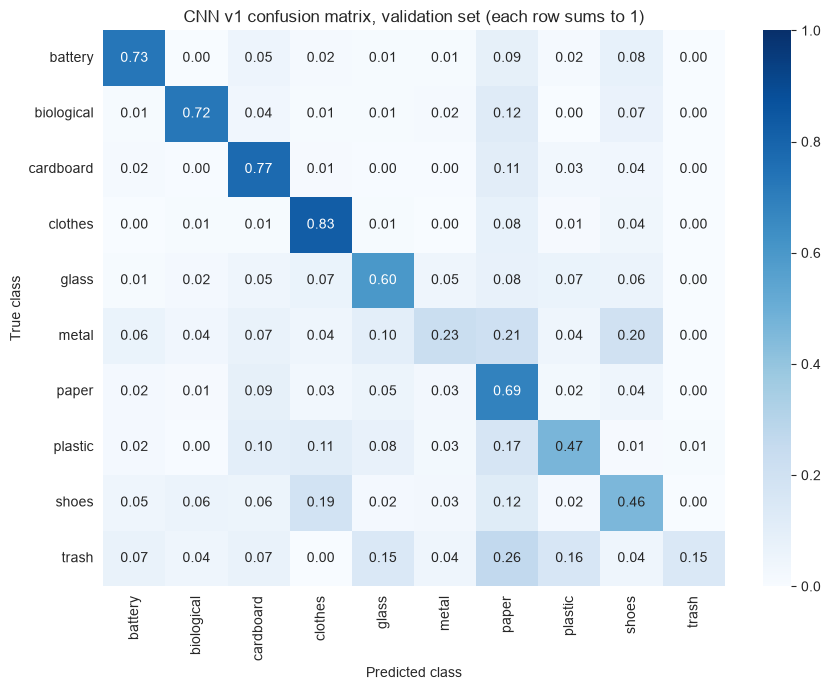

In [26]:
pred_v1_val = prob_v1_val.argmax(1)
print(classification_report(y_val, pred_v1_val, target_names=CLASSES, digits=3))

# normalize="true" divides each row by its class size, so the diagonal is each class's recall
cm = confusion_matrix(y_val, pred_v1_val, normalize="true")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, vmin=0, vmax=1)
ax.set_title("CNN v1 confusion matrix, validation set (each row sums to 1)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_cnn_v1_val.png"), dpi=100)
plt.show()

### Per-class and confusion matrix interpretation

On validation CNN v1 gets 60.1% accuracy and a macro F1 of 0.560, against 0.440 for the shortcut forest. The classes fall into three groups:

- **Doing well** (F1 about 0.70 to 0.75): clothes (recall 0.827), cardboard (0.774), battery (0.728), biological (0.724).
- **Middling:** glass (F1 0.650), plastic (0.549), paper (0.509), shoes (0.484).
- **Failing:** metal (recall 0.230) and trash (recall 0.147). The model finds only 10 of the 68 trash images.

The confusion matrix shows where the misses go. Paper works like a default answer: 26% of trash, 21% of metal and 17% of plastic are predicted as paper, which is why paper's precision is only 0.405 even though its recall is 0.687. The other big leaks are metal to shoes (20%), shoes to clothes (19%), and trash to plastic (16%) and glass (15%). The author found paper and plastic the most confused pair [1]. Here plastic does go to paper 17% of the time, but paper hardly ever goes to plastic (2%), so for my model the confusion runs one way.

Each error costs something different at a sorting point. Trash predicted as paper or plastic contaminates a recycling stream. Metal predicted as shoes or paper loses a recyclable with resale value. A battery predicted as anything else is the dangerous one (Section 17), and on validation 27% of batteries are missed, mostly to paper (9%) and shoes (8%).

The two failing classes only partly fit the imbalance story. Trash is the smallest class (317 training images), but metal has 651, more than battery or biological, and still fails. Metal reflects whatever is around it, so a can or a sheet of foil takes on the look of its background, and trash is the most varied class. So class weights may help trash more than metal. **What could make me wrong:** these are validation numbers from one training run. Trash recall of 0.147 is 10 images, and a different seed could move it by several points.

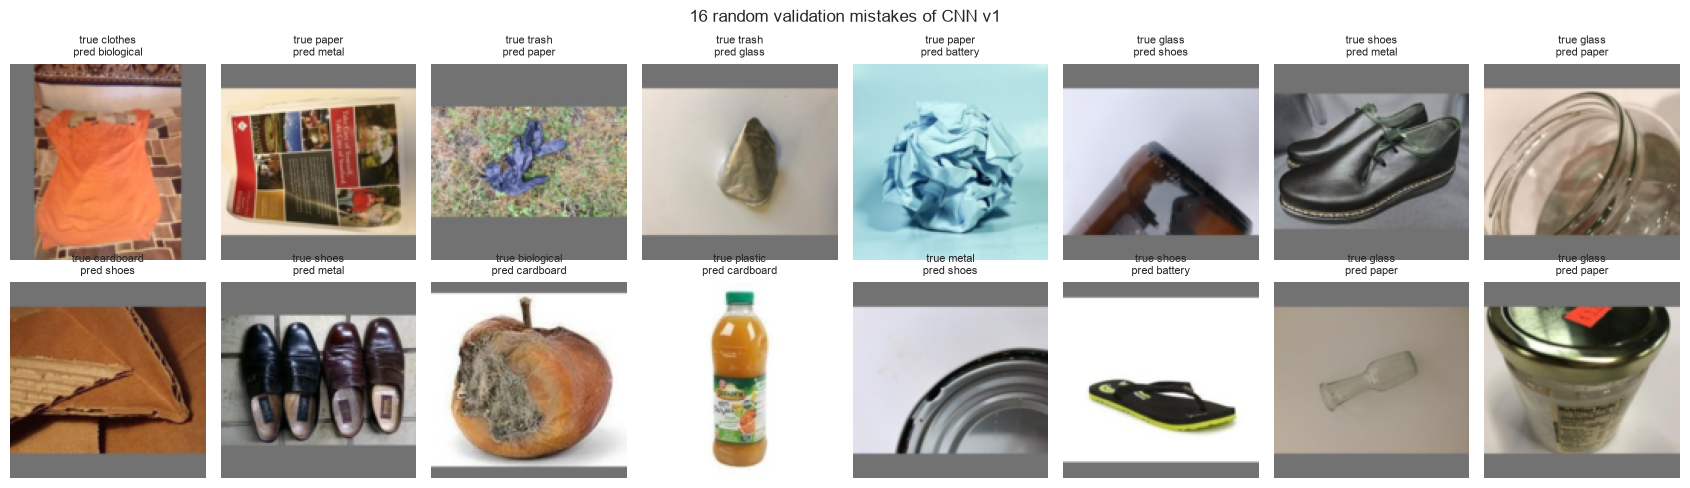

In [27]:
wrong = np.where(pred_v1_val != y_val)[0]
# A random sample of mistakes, not the worst ones, so the gallery isn't cherry-picked
pick = np.random.default_rng(SEED).choice(wrong, size=min(16, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 8, figsize=(17, 5))
for ax, k in zip(axes.ravel(), pick):
    ax.imshow(X_val[k])
    ax.set_title(f"true {CLASSES[y_val[k]]}\npred {CLASSES[pred_v1_val[k]]}", fontsize=8)
    ax.axis("off")
plt.suptitle("16 random validation mistakes of CNN v1")
plt.tight_layout()
plt.show()

### Mistakes gallery interpretation

Most of these are understandable mistakes. A purple glove on grass (trash) becomes paper, a crumpled light-blue sheet (paper) becomes battery, a curved piece of glass becomes paper, and a pair of shiny leather shoes becomes metal. Several are close-ups with no context at all, like the edge of a metal lid. I don't see a wrong label in these 16. What I do see is a model that reacts to surface and colour more than to outline, which fits a small network trained from scratch for 30 epochs.

### How sure can I be of these numbers?

One test set gives one number per metric. To see how much those numbers would move with a different sample of images, I use the bootstrap: draw 1,839 test images *with replacement* 1,000 times, score the model each time, and take the middle 95% of the scores as the interval. To compare two models on the same images I use McNemar's test, which looks only at the images where one model is right and the other wrong. Dietterich found it has a low chance of a false alarm when each model can only be trained once [7], which is my situation.

In [28]:
# Bootstrap: resample the test images with replacement and recompute the metric each time
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
                # n random positions drawn with replacement: some images appear twice, some not at all
        s = rng.integers(0, n, n)
        vals.append(metric(y_true[s], y_pred[s]))
        # The middle 95% of the 1,000 scores is the interval
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)


# McNemar only uses the images where exactly one of the two models is right
def mcnemar_test(y_true, pred_a, pred_b):
        # The 2 x 2 table: both right, only A right, only B right, both wrong
    a_right, b_right = pred_a == y_true, pred_b == y_true
    table = [[np.sum(a_right & b_right), np.sum(a_right & ~b_right)],
             [np.sum(~a_right & b_right), np.sum(~a_right & ~b_right)]]
    # With few disagreements the exact version is safer than the chi-square one
    exact = (table[0][1] + table[1][0]) < 25
    res = mcnemar(table, exact=exact, correction=not exact)
    return table[0][1], table[1][0], res.pvalue


# Macro F1 averages the ten per-class F1 scores, so every class counts the same
macro_f1 = lambda yt, yp: f1_score(yt, yp, average="macro")
print("Bootstrap function and McNemar test ready")

Bootstrap function and McNemar test ready


I test them on the shortcut forest first, because its predictions exist without any training. This checks the code and gives the shortcut model's own interval.

In [29]:
lo, hi = bootstrap_ci(y_test, pred_forest_test, macro_f1)
print(f"Shortcut forest test macro F1: {macro_f1(y_test, pred_forest_test):.3f} (95% interval {lo:.3f} to {hi:.3f})")

Shortcut forest test macro F1: 0.456 (95% interval 0.429 to 0.478)


On the test set the shortcut forest scores a macro F1 of 0.456, with a 95% interval of 0.429 to 0.478. That width, about 0.05, is a useful reference: it's roughly how far any test macro F1 in this notebook can move just because of which 1,839 images happened to be drawn. A gap between two models smaller than that needs the paired McNemar test before I believe it.

## 14. Retraining (CNN v2)

v1 has two shortcomings, and on the same split I can only change one thing at a time:

1. **Trash and metal are barely found** (validation recall 0.147 and 0.230), while the big classes do well.
2. **It was still improving at epoch 30** (Section 12).

I chose to fix the first. It's the one the press would notice: a sorter that almost never says "trash" sends general waste into the recycling bins. Training for longer would probably lift every class a little, but it would add another 45 minutes or more and wouldn't target the small classes.

The change: **class weights**. Each training image counts in the loss in inverse proportion to how common its class is, so a trash image counts about four times as much as a clothes image. Everything else stays the same: same split, same seed, same architecture, same stopping rule. Only one thing changes, so any difference can be put down to it (within the one-run caveat from Section 12).

In [30]:
# "balanced" gives each class the weight n_images / (n_classes x images_in_class)
weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print(pd.Series(weights, index=CLASSES).round(2).to_string())

cnn_v2, hist_v2 = train_or_load("cnn_v2", build_cnn, class_weight=class_weight)
prob_v2_val = cnn_v2.predict(X_val, verbose=0)
prob_v2_test = cnn_v2.predict(X_test, verbose=0)
np.save(os.path.join(ARTIFACTS, "prob_cnn_v2_val.npy"), prob_v2_val)
np.save(os.path.join(ARTIFACTS, "prob_cnn_v2_test.npy"), prob_v2_test)
results["CNN v2 (class weights)"] = {"val": scores(y_val, prob_v2_val.argmax(1)), "test": scores(y_test, prob_v2_test.argmax(1))}
print("---")
print("Epochs run:", len(hist_v2["loss"]), "| best epoch:", int(np.argmin(hist_v2["val_loss"])) + 1)
print("Validation:", {k: round(v, 4) for k, v in results["CNN v2 (class weights)"]["val"].items()})

battery       1.62
biological    1.75
cardboard     0.87
clothes       0.65
glass         0.71
metal         1.32
paper         0.92
plastic       0.77
shoes         0.85
trash         2.71
Epoch 1/30
269/269 - 126s - 469ms/step - accuracy: 0.1507 - loss: 2.2088 - val_accuracy: 0.2561 - val_loss: 2.1163
Epoch 2/30
269/269 - 180s - 667ms/step - accuracy: 0.2349 - loss: 2.0446 - val_accuracy: 0.2985 - val_loss: 1.9722
Epoch 3/30
269/269 - 120s - 446ms/step - accuracy: 0.2783 - loss: 1.9295 - val_accuracy: 0.3594 - val_loss: 1.8436
Epoch 4/30
269/269 - 114s - 423ms/step - accuracy: 0.3133 - loss: 1.8747 - val_accuracy: 0.3719 - val_loss: 1.7918
Epoch 5/30
269/269 - 115s - 428ms/step - accuracy: 0.3580 - loss: 1.8063 - val_accuracy: 0.3611 - val_loss: 1.7737
Epoch 6/30
269/269 - 115s - 428ms/step - accuracy: 0.3706 - loss: 1.7566 - val_accuracy: 0.3953 - val_loss: 1.7094
Epoch 7/30
269/269 - 116s - 432ms/step - accuracy: 0.3921 - loss: 1.6971 - val_accuracy: 0.4192 - val_loss: 1.6455
Epoch

In [31]:
pred_v2_val = prob_v2_val.argmax(1)
recall_compare = pd.DataFrame({
    "v1 recall": recall_score(y_val, pred_v1_val, average=None),
    "v2 recall": recall_score(y_val, pred_v2_val, average=None),
    "validation images": np.bincount(y_val)}, index=CLASSES)
recall_compare["change"] = recall_compare["v2 recall"] - recall_compare["v1 recall"]
print(recall_compare.round(3).sort_values("v1 recall").to_string())
print("---")
b, c, p = mcnemar_test(y_val, pred_v1_val, pred_v2_val)
print(f"Validation McNemar v1 vs v2: v1 right/v2 wrong = {b}, v1 wrong/v2 right = {c}, p = {p:.4f}")

# The rule from the plan: the higher validation macro F1 is the model I report on the test set
# The test set plays no part in this choice
final_name = "CNN v2 (class weights)" if results["CNN v2 (class weights)"]["val"]["macro_f1"] > results["CNN v1"]["val"]["macro_f1"] else "CNN v1"
final_prob_test = prob_v2_test if final_name.startswith("CNN v2") else prob_v1_test
final_model = cnn_v2 if final_name.startswith("CNN v2") else cnn_v1
final_pred_test = final_prob_test.argmax(1)
print("Model chosen on validation macro F1:", final_name)

            v1 recall  v2 recall  validation images  change
trash           0.147      0.559                 68   0.412
metal           0.230      0.482                139   0.252
shoes           0.459      0.326                218  -0.133
plastic         0.469      0.456                239  -0.013
glass           0.600      0.512                260  -0.088
paper           0.687      0.657                201  -0.030
biological      0.724      0.686                105  -0.038
battery         0.728      0.746                114   0.018
cardboard       0.774      0.745                212  -0.028
clothes         0.827      0.756                283  -0.071
---
Validation McNemar v1 vs v2: v1 right/v2 wrong = 187, v1 wrong/v2 right = 161, p = 0.1802
Model chosen on validation macro F1: CNN v2 (class weights)


### Retrain interpretation

Class weights did what they were meant to do for the weak classes. On validation, trash recall rose from 0.147 to 0.559 and metal from 0.230 to 0.482. It came at a price: shoes fell from 0.459 to 0.326, clothes from 0.827 to 0.756 and glass from 0.600 to 0.512. Validation macro F1 went up from 0.560 to 0.579 while accuracy went down from 60.1% to 58.7%. v2's best epoch was 28 of 30, so it also ran close to the limit.

McNemar's test on validation gives p = 0.180 (v1 right where v2 was wrong on 187 images, the reverse on 161), so the two models don't clearly differ in how many images they get right; they get different ones right. By the plan's rule, the higher validation macro F1, v2 is the model I take to the test set.

**What could make me wrong:** the macro F1 gain is 0.019, and with one run per model that is within the shift a different seed could cause.

### All models on the test set

Now, and only now, the test set. Each row has its macro F1 with a bootstrap interval, and the McNemar tests compare the chosen CNN with the shortcut forest and v1 with v2.

In [32]:
test_preds = {"Majority class": pred_major_test, "Shortcut forest": pred_forest_test,
              "Dense network": prob_dense_test.argmax(1), "CNN v1": prob_v1_test.argmax(1),
              "CNN v2 (class weights)": prob_v2_test.argmax(1)}
rows = []
for name, pred in test_preds.items():
        # Same bootstrap for every model, so the intervals are comparable
    lo, hi = bootstrap_ci(y_test, pred, macro_f1)
    rows.append({"model": name, "val macro F1": results[name]["val"]["macro_f1"],
                 "test accuracy": accuracy_score(y_test, pred), "test macro F1": macro_f1(y_test, pred),
                 "95% interval": f"{lo:.3f} to {hi:.3f}"})
summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(ARTIFACTS, "model_summary.csv"), index=False)
print(summary.round(3).to_string(index=False))
print("---")
for a, b_name in [("Shortcut forest", final_name), ("CNN v1", "CNN v2 (class weights)"), ("Dense network", final_name)]:
    n_b, n_c, p = mcnemar_test(y_test, test_preds[a], test_preds[b_name])
    print(f"McNemar {a} vs {b_name}: only {a} right = {n_b}, only {b_name} right = {n_c}, p = {p:.4g}")

                 model  val macro F1  test accuracy  test macro F1   95% interval
        Majority class         0.027          0.154          0.027 0.024 to 0.029
       Shortcut forest         0.440          0.487          0.456 0.429 to 0.478
         Dense network         0.331          0.387          0.316 0.297 to 0.335
                CNN v1         0.560          0.624          0.588 0.564 to 0.611
CNN v2 (class weights)         0.579          0.598          0.590 0.567 to 0.612
---
McNemar Shortcut forest vs CNN v2 (class weights): only Shortcut forest right = 282, only CNN v2 (class weights) right = 485, p = 3.013e-13
McNemar CNN v1 vs CNN v2 (class weights): only CNN v1 right = 170, only CNN v2 (class weights) right = 122, p = 0.005951
McNemar Dense network vs CNN v2 (class weights): only Dense network right = 133, only CNN v2 (class weights) right = 520, p = 1.493e-51


### Test results interpretation

The CNN clearly beats every baseline. v2's test macro F1 is 0.590 against 0.456 for the shortcut forest, and their intervals don't overlap. McNemar's test agrees: of the test images where only one of the two is right, v2 wins 485 and the forest 282 (p = 3.0e-13). Against the dense network the gap is wider still (520 against 133). So the convolution layers learnt something about the images that file size, brightness and shape can't explain, which answers the main worry from Section 11.

Between the two CNNs the picture is mixed. Their macro F1 is almost identical (0.588 and 0.590, with intervals that overlap almost completely), but v1 gets more images right: 62.4% against 59.8% accuracy, and McNemar's test says that gap is real (v1 alone right on 170 images, v2 alone on 122, p = 0.006). That's the trade class weights make. v2 gives up some easy clothes and shoes to find more trash and metal. Which one is "better" depends on what each mistake costs, which is a business question for Section 17, not a statistical one. My honest reading is that v2 is **not better overall; it's better balanced.**

The author's best result was 95.13% accuracy with a pretrained EfficientNetV2S [1]. 59.8% is far below that, but it isn't a like-for-like comparison: their network started from weights learnt on millions of other images, while mine learnt from 8,581 images on a laptop CPU in 44.5 and 63.3 minutes. **What could make me wrong:** beating the shortcut forest shows the CNN uses more than file information, not that it ignores it. The stress tests and the confident mistakes are the next check.

## 15. Stress tests

The test images are clean photos like the training ones. A sorting point won't be. Here I change every test image in one way at a time and score the chosen model again. Nothing is retrained; this only shows how the same model copes.

| Condition | What I do | Why it matters at a sorting point |
|---|---|---|
| Darker | pixel values x 0.6 | Inside a bin, under a counter |
| Brighter | pixel values x 1.4, capped at 255 | Sunlight, flash |
| Blurred | Gaussian blur, radius 1.5 pixels | A moving hand, a cheap lens |
| Rotated 15 degrees | rotated, corners filled with the padding grey | Items don't arrive straight |
| JPEG quality 30 | saved and reloaded as a heavily compressed JPEG | Low-bandwidth cameras |

In [33]:
# Saving to memory with a low quality setting and reading it back adds real JPEG blocking and smearing
def jpeg(img, q):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=q)
    return Image.open(buf)


conditions = {
    "clean": lambda im: im,
        # Multiplying every pixel scales brightness while keeping the picture itself
    "darker": lambda im: Image.fromarray((np.asarray(im, dtype=np.float32) * 0.6).astype(np.uint8)),
    "brighter": lambda im: Image.fromarray(np.clip(np.asarray(im, dtype=np.float32) * 1.4, 0, 255).astype(np.uint8)),
    "blurred": lambda im: im.filter(ImageFilter.GaussianBlur(1.5)),
    # Fill the corners with the same grey as the dataset's padding, so the fill isn't a new cue
        # A positive angle turns the image anticlockwise
    "rotated 15": lambda im: im.rotate(15, fillcolor=(114, 114, 114)),
    "JPEG q30": lambda im: jpeg(im, 30),
}
stress_rows = []
for name, fn in conditions.items():
        # Every test image gets the same change, then the unchanged model predicts them
    X_mod = np.stack([np.asarray(fn(Image.fromarray(x)).convert("RGB")) for x in X_test])
    pred = final_model.predict(X_mod, verbose=0).argmax(1)
    stress_rows.append({"condition": name, "macro F1": macro_f1(y_test, pred), "accuracy": accuracy_score(y_test, pred),
                        "battery recall": recall_score(y_test, pred, labels=[CLASSES.index("battery")], average="macro")})
stress = pd.DataFrame(stress_rows)
# Drop compared with the clean test set, in percentage points
stress["macro F1 drop (points)"] = (stress.loc[0, "macro F1"] - stress["macro F1"]) * 100
stress.to_csv(os.path.join(ARTIFACTS, "stress_tests.csv"), index=False)
print("Model:", final_name)
print(stress.round(3).to_string(index=False))

Model: CNN v2 (class weights)
 condition  macro F1  accuracy  battery recall  macro F1 drop (points)
     clean     0.590     0.598           0.752                   0.000
    darker     0.380     0.420           0.159                  21.002
  brighter     0.475     0.490           0.708                  11.493
   blurred     0.455     0.494           0.469                  13.516
rotated 15     0.565     0.570           0.743                   2.478
  JPEG q30     0.585     0.591           0.717                   0.550


### Stress test interpretation

Three of the five changes break my 10-point rule:

- **Darker** costs 21.0 macro-F1 points (0.590 to 0.380), and battery recall collapses from 0.752 to 0.159. In the dark the model finds about one battery in six.
- **Blurred** costs 13.5 points, with battery recall down to 0.469.
- **Brighter** costs 11.5 points, although battery recall holds up (0.708).

Rotating by 15 degrees (2.5 points) and heavy JPEG compression (0.6 points) barely matter.

The darker result is the most important finding for the press, and it matches the EDA: only 1.0% of training images have a mean grey level below 60, and battery images are the brightest class (median 195.2). The model seems to have learnt "bright, white background" as part of what a battery looks like, and a battery at the bottom of a bin doesn't look like that. My brightness augmentation (up to 20%) was too mild to cover a 40% drop.

**Decision:** dark and blurred photos are deployment risks, so a camera at a sorting point would need its own lighting. **What could make me wrong:** multiplying the pixels by 0.6 is a crude stand-in for a dark bin. Real low light also adds noise and colour shifts, which would probably make things worse, not better.

## 16. Label check on confident mistakes

If the model is very sure and still "wrong", either the model has learned something misleading or the label is wrong. Northcutt et al. found label errors this way in well-known test sets [4]. Here are the 20 test images the chosen model got wrong with the highest confidence. I judge each by eye.

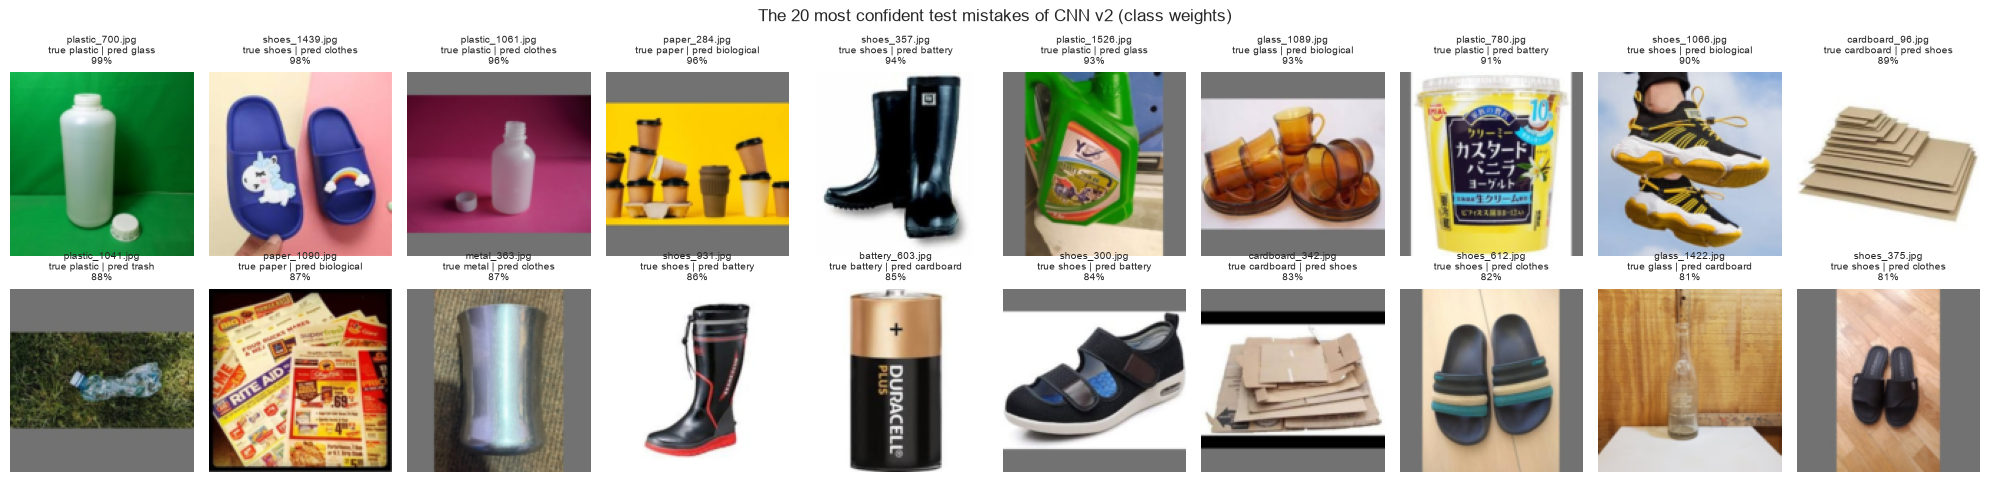

In [34]:
conf = final_prob_test.max(1)
wrong_test = np.where(final_pred_test != y_test)[0]
# Sort the wrong answers by how sure the model was, most confident first
top = wrong_test[np.argsort(-conf[wrong_test])][:20]
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
for ax, k in zip(axes.ravel(), top):
    ax.imshow(X_test[k])
    ax.set_title(f"{meta['file'].values[idx_test[k]]}\ntrue {CLASSES[y_test[k]]} | pred {CLASSES[final_pred_test[k]]}\n{conf[k]:.0%}", fontsize=7)
    ax.axis("off")
plt.suptitle(f"The 20 most confident test mistakes of {final_name}")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confident_mistakes.png"), dpi=100)
plt.show()
pd.DataFrame({"file": meta["file"].values[idx_test[top]], "true": [CLASSES[i] for i in y_test[top]],
              "predicted": [CLASSES[i] for i in final_pred_test[top]], "confidence": conf[top].round(3)}
             ).to_csv(os.path.join(ARTIFACTS, "confident_mistakes.csv"), index=False)

### Label check interpretation

I looked at all 20. None is clearly a wrong label. One is debatable: `paper_284` shows takeaway coffee cups labelled paper, and those cups are usually lined with plastic, so "paper" is a judgement call, like the cartons labelled cardboard. The other 19 are labelled correctly and the model is confidently wrong. Two things follow.

1. On this small check the volunteer labels hold up: no clear errors and one debatable label among the model's 20 most confident mistakes. That's far smaller than Northcutt et al.'s study [4], so it can't give an error rate, but it gives me no reason to think label noise is distorting the test score.
2. The confident mistakes follow backgrounds and colours, not objects. A white plastic bottle on a green background is called glass at 99% confidence (`plastic_700`), and a green plastic jerry can is called glass too (`plastic_1526`). Amber glass cups are called biological (`glass_1089`), the colour of fruit. Black rubber boots on white become battery (`shoes_357`, `shoes_931`), the look of a product photo. A glass bottle on a wooden table becomes cardboard (`glass_1422`). A crushed plastic bottle on grass becomes trash (`plastic_1041`), and trash photos are often taken on grass. Three slides photographed on floors become clothes.

This is the shortcut problem from Sections 8 and 11, now visible in the pixels: colour and background carry a lot of the decision. **What could make me wrong:** 20 images is a small and selected sample. It shows what the model does when it is most wrong, not how it decides on average.

## 17. Business reading

Accuracy treats every mistake the same. A sorting point doesn't. **My assumption: a battery sorted into an ordinary bin costs ten times as much as any other wrong sort**, because lithium cells crushed in a waste truck can start fires, while putting paper in the plastic bin only lowers the quality of the recycling. So I report battery recall on its own and a cost per 1,000 items with that weighting. The ratio of ten is my judgement, not a measured figure, so I also say whether the ranking of the models changes with it.

In [35]:
b = CLASSES.index("battery")
# Cost matrix: 0 for a right answer, 10 for a battery sent anywhere else, 1 for every other mistake
# Rows are the true class, columns the predicted class
cost = np.ones((len(CLASSES), len(CLASSES)))
np.fill_diagonal(cost, 0)
cost[b, :] = 10
cost[b, b] = 0

rows = []
for name, pred in test_preds.items():
        # Raw counts this time, because cost is counted per item
    counts_cm = confusion_matrix(y_test, pred, labels=np.arange(len(CLASSES)))
        # Batteries correctly sent to the battery bin, out of all batteries
    bat_rec = counts_cm[b, b] / counts_cm[b].sum()
    lo, hi = bootstrap_ci(y_test[y_test == b], pred[y_test == b], accuracy_score)
    rows.append({"model": name, "battery recall": bat_rec, "battery recall 95% interval": f"{lo:.3f} to {hi:.3f}",
                 "cost per 1,000 items (ratio 10)": (counts_cm * cost).sum() / len(y_test) * 1000,
                                  # Ratio 1 treats every mistake the same, so I can see if the weighting changes the ranking
                 "cost per 1,000 items (ratio 1)": (counts_cm * (cost > 0)).sum() / len(y_test) * 1000})
business = pd.DataFrame(rows)
print(business.round(3).to_string(index=False))
print("---")
# The battery row of the confusion matrix shows which bins the missed batteries would go to
final_cm = confusion_matrix(y_test, final_pred_test, labels=np.arange(len(CLASSES)))
print(f"Where {final_name} sends test batteries:")
print(pd.Series(final_cm[b], index=CLASSES).to_string())

                 model  battery recall battery recall 95% interval  cost per 1,000 items (ratio 10)  cost per 1,000 items (ratio 1)
        Majority class           0.000              0.000 to 0.000                         1398.586                         845.568
       Shortcut forest           0.310              0.221 to 0.407                          894.508                         512.779
         Dense network           0.327              0.248 to 0.416                          984.774                         612.833
                CNN v1           0.699              0.619 to 0.779                          542.686                         376.291
CNN v2 (class weights)           0.752              0.673 to 0.832                          539.424                         402.393
---
Where CNN v2 (class weights) sends test batteries:
battery       85
biological     3
cardboard      6
clothes        1
glass          2
metal          5
paper          5
plastic        3
shoes          0


### Business interpretation

**Battery recall.** v2 finds 75.2% of test batteries (95% interval 67.3% to 83.2%) and v1 69.9% (61.9% to 77.9%). Put plainly, v2 still misses about 1 battery in 4: 28 of the 113 test batteries, sent mostly to cardboard (6), metal (5) and paper (5). The two intervals overlap a lot, so I can't claim v2 is safer on batteries, only that it isn't worse. For comparison, the shortcut forest finds 31.0% and the dense network 32.7%.

**Cost.** With the ten-to-one weighting, v2 and v1 cost almost the same per 1,000 items (539.4 and 542.7). With every mistake counted the same, v1 is cheaper (376.3 against 402.4). So the weighting does flip the order, but at ratio 10 only by a hair. The choice between the two CNNs depends on how much the press thinks a missed battery really costs.

**What this means for the press.** Neither model is safe enough to sort batteries on its own. Missing one battery in four in good light, and five in six in the dark, means a person has to check anything heading for general waste, or batteries need their own drop-off point that doesn't depend on a camera. The model is more useful as an assistant at a staffed sorting point than as an automatic sorter. Two decisions belong to the press rather than to me: whether drink cartons count as cardboard at their premises (the dataset says they do), and what a missed battery costs compared with a contaminated recycling bag.

**What could make me wrong:** the test batteries are mostly product photos on white. A real battery in a bin is smaller, dirtier and darker, so its real recall is likely lower than 75.2%.

## 18. Conclusion and limitations

### Revisiting the hypothesis

I expected three things.

1. **A small CNN would clearly beat the simple baselines.** It did. Test macro F1 was 0.590 against 0.456 for the shortcut forest and 0.316 for the dense network, with McNemar p-values far below 0.05.
2. **Its mistakes would gather in materials that look alike**, such as paper and cardboard or glass and plastic. Only partly. Those pairs do mix (plastic to paper 17% and cardboard to paper 11% on validation), but the bigger patterns were paper acting as a default answer and mistakes driven by colour and background: green to glass, orange to biological, white backgrounds to battery.
3. **Part of what the model learns would be how a photo was taken.** The evidence supports this. Five file-level numbers alone reach a test macro F1 of 0.456, the most confident mistakes follow backgrounds, and a darker test set cuts macro F1 by 21.0 points and battery recall to 0.159.

So the CNN is a real improvement on the shortcuts, and it still leans on them.

### Limitations, and how much each one matters

- **One training run per model.** v1 and v2 differ by 0.002 in test macro F1, well inside what a different seed could change. The accuracy gap (p = 0.006) is the only CNN-against-CNN result I'd defend, and McNemar only covers test-set noise.
- **Both CNNs were still improving at the 30-epoch limit.** Their scores are probably a few points below what this architecture could reach. That doesn't change the ranking against the baselines, but 59.8% isn't a ceiling.
- **A random split that mixes sources.** About 18% of images probably come from one studio set-up (TrashNet), and that look is in both training and test, so the test score measures familiar kinds of photo. Performance on the press's own camera is unknown and probably lower.
- **Near-duplicates across the split.** 5 test images have a near-twin in training, worth at most 0.3 points of accuracy.
- **Clean, single-item photos.** The stress tests show dark and blurred photos cost 13.5 to 21.0 points, and real bins are both.
- **Classes that don't match a press's waste.** There is no class for toner or ink cartridges, and clothes and shoes are rare at a press.
- **The ten-to-one cost ratio is my assumption.** It decides which CNN looks cheaper.

### What I'd do next

In order of value to the press: collect a few hundred photos from its own sorting point, in its own light, and test on those before anything else; add much stronger darkening and blur to the augmentation, because those caused the biggest drops; train for longer, because both CNNs were still improving; and try a network pretrained on other images, which is what the author used [1], as the next model rather than a bigger one from scratch.

## 19. References

[1] S. Kunwar, "The Garbage Dataset (GD): A multi-class image benchmark for automated waste segregation," *J. Braz. Comput. Soc.*, vol. 32, no. 1, Jun. 2026, doi: 10.5753/jbcs.2026.7774.

[2] G. Thung and M. Yang, "trashnet: Dataset of images of trash," GitHub repository. https://github.com/garythung/trashnet (accessed Nov. 19, 2026).

[3] R. Geirhos, J.-H. Jacobsen, C. Michaelis, R. Zemel, W. Brendel, M. Bethge, and F. A. Wichmann, "Shortcut learning in deep neural networks," *Nat. Mach. Intell.*, vol. 2, no. 11, pp. 665–673, 2020, doi: 10.1038/s42256-020-00257-z.

[4] C. G. Northcutt, A. Athalye, and J. Mueller, "Pervasive label errors in test sets destabilize machine learning benchmarks," in *Proc. 35th Conf. Neural Inf. Process. Syst. (NeurIPS) Track on Datasets and Benchmarks*, 2021. [Online]. Available: https://arxiv.org/abs/2103.14749

[5] D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. 3rd Int. Conf. Learn. Represent. (ICLR)*, 2015. [Online]. Available: https://arxiv.org/abs/1412.6980

[6] N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, and R. Salakhutdinov, "Dropout: A simple way to prevent neural networks from overfitting," *J. Mach. Learn. Res.*, vol. 15, no. 56, pp. 1929–1958, 2014.

[7] T. G. Dietterich, "Approximate statistical tests for comparing supervised classification learning algorithms," *Neural Comput.*, vol. 10, no. 7, pp. 1895–1923, Oct. 1998, doi: 10.1162/089976698300017197.